# Validating our own measures

Before writing the paper, this notebook checks the measures we designed ourselves: does a conclusion depend on how we
defined a score, on how we picked the heads, or on missing controls?

**Part 1. Learning score vs. raw numbers.** Our learning score is normalized: (phase mean − baseline) ÷
(bound − baseline). Is the jump at layer 19 also there in the raw numbers, and with other normalizations?

**Part 2. Induction score vs. Olsson et al. (2022).** Our copying score is our own (rank-based, on a head's direct
path). We compare it with the standard one: the eigenvalues of each head's OV circuit. Then we compare head selections:
our top 16, Olsson-style thresholds, and prefix matching alone.

**Part 3. Controls for our new analyses.**
- Reading map: random heads, and a permutation baseline.
- Leave-one-in: random heads given back.
- FDR correction (Benjamini–Hochberg) for every heatmap with significance stars, and the number of significant
  cells in the random controls.
- Noise: paired per-run differences with 95% bootstrap intervals, and a paired test of layers 15–18 vs. 19–22.

**Run order and time (Colab T4, 8-bit model), about 3–3.5 h in total:**

| Step | Time |
|---|---|
| Setup and model | ~10 min |
| Part 1 (all-layer logit and tuned lens, 20 runs per grammar) | ~30–45 min |
| Part 2 (OV eigenvalues, plus ~10 min only if the threshold set differs from the top 16) | ~5 min |
| Part 3a: reading map | ~10 min |
| Part 3b: leave-one-in controls | ~30 min |
| Part 3c: FDR (results loaded from Drive) | ~0 min |
| Part 3d: noise | ~75 min |

The cell after the settings measures the real time per run and prints an estimate per part. Everything is saved to
Drive as it goes; after a disconnect: reconnect, **Runtime → Run all**, approve the Drive popup, and finished parts
load in seconds.

In [51]:
# Stop right away if there is no GPU (NVIDIA in Colab, or an Apple Silicon Mac): on CPU the 7B model does not
# fit in memory and loading stalls.
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # less memory fragmentation
import torch
REQUIRE_GPU = True
if torch.cuda.is_available():
  print(f"GPU: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
  print("GPU: Apple Silicon (MPS); the model runs in float16 (8-bit loading needs an NVIDIA GPU)")
elif REQUIRE_GPU:
  raise RuntimeError("No GPU. In Colab: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all. "
                     "If Colab says no GPU is available, its free GPU quota is used up for now: try again later.")

# Google Drive first: Colab asks for permission once per new runtime. Approve the popup right away;
# "Run all" waits here until you do. Everything slow (tuned lens, lens results) is saved there.
USE_GOOGLE_DRIVE = True
DRIVE_CACHE_DIR = '/content/drive/MyDrive/plasticity_lens_cache'
if USE_GOOGLE_DRIVE:
  try:
    from google.colab import drive
    drive.mount('/content/drive')
  except ImportError:
    print("not running in Colab; results are saved locally")

!pip install -q -U bitsandbytes
!pip install -q datasets  # tuned-lens training text


GPU: Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Import packages

In [52]:
import json
import random
from tqdm import tqdm
random.seed(42)

## Set run parameters

In [53]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
LOAD_IN_8BIT_ON_CUDA = True  # set False if your GPU has enough memory for full float16 (e.g. A100/L4); needed on a free-tier T4 (14.5GB) to avoid OOM
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [54]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    import spacy  # only needed for tokens_type "all_nouns"/"all_verbs" (requires en_core_web_trf)
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [55]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'air

In [56]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

## Generate Sequences

In [57]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [58]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [59]:
def build_random_DFA(vocab):
  vocab_copy = sorted(vocab)  # fixed order: iterating a set of strings changes between Python sessions
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [60]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [61]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [62]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### AGL word streams

In [63]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

100%|██████████| 100/100 [00:01<00:00, 60.51it/s]


In [64]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]  # same as meeting 1

output = {"shuffle": []}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  output["shuffle"].append(prompt_dict.copy())
  output["shuffle"][-1]["mapped_prompt"] = map_prompt(prompt_dict["placeholder_prompt"], shuffle_vocab[i])
  output["shuffle"][-1]["vocab"] = shuffle_vocab[i]


### SRTT word streams

In [65]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [66]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [67]:
# NOTE: all SRTT runs share ONE generated sequence (including the random baseline/post segments);
# only the vocabulary differs between runs, so averaging over runs averages over vocabularies,
# not over random sequences. (The SRTT cells below also assume equal-length runs.)
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]


In [68]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

## Load the model

In [69]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [70]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [71]:
import logging
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)  # silences repeated per-matmul cast-precision
                                                              # logging noise from the 8-bit quantized model;
                                                              # purely cosmetic, no effect on results

In [72]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  if device == 'cuda' and LOAD_IN_8BIT_ON_CUDA:
    from transformers import BitsAndBytesConfig
    quantization_config = BitsAndBytesConfig(load_in_8bit=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, quantization_config=quantization_config, low_cpu_mem_usage=True)
  else:
    dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [73]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


device: cuda
loading mistral...


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

LOADING DONE!
Model: mistralai/Mistral-7B-v0.3
Context window length: 32768
Number of parameters: 7,248,023,552
Hugging Face URL: https://huggingface.co/mistralai/Mistral-7B-v0.3


In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14})


## Shared tools from the lens notebooks

The next cells are copied unchanged from `02_tuned_lens`: settings and Google Drive caching, the logit lens
(`get_layer_logits`), the per-run extraction with saving and resuming (`run_lens_extraction`), the per-layer
summary (`lens_phase_summary`), the plotting helpers, and the Wikipedia text loader (`load_lens_training_tokens`).
The tuned lens itself is not used here.

In [75]:
import os

LAYERS_TO_DECODE = 'all'  # 'all' decodes every layer (0 = embedding output, 1..32 = after each transformer block);
                          # or set a list like [0, 8, 16, 24, 32] for a lighter run
LENS_CACHE_DIR = 'lens_cache'  # per-condition results are pickled here and reloaded if the inputs match;
                               # point it at a mounted Google Drive folder to survive a Colab reconnect. None = off
LAST_N_STRUCTURED = 1000  # summary window: last (and first) N tokens of the structured phase
BASELINE_WARMUP = 50  # skip the first N baseline tokens (the model has not seen the alphabet yet; full-vocab P climbs from ~0)

# Tuned lens (trained once on generic text, never on the grammar task; see "Tuned lens" below)
TUNED_LENS_DATASET = ("Salesforce/wikitext", "wikitext-103-raw-v1")  # (HF dataset, config), streamed
TUNED_LENS_STEPS = 400        # optimizer steps (~40 min on a T4)
TUNED_LENS_BATCH = 2          # sequences per step (2 x 512 fits a 15 GB T4 next to the 8-bit model)
TUNED_LENS_SEQ_LEN = 512      # tokens per sequence (BOS + 511)
TUNED_LENS_POSITIONS_PER_SEQ = 128  # train on a random subset of positions per sequence: the lens (not the model)
                                    # is most of the cost per position, and neighbouring positions are redundant
TUNED_LENS_LR = 1.0           # SGD with Nesterov momentum, linear decay to 0 (as in Belrose et al. 2023)
TUNED_LENS_MOMENTUM = 0.9
TUNED_LENS_WEIGHT_DECAY = 1e-3
TUNED_LENS_VAL_SEQS = 16      # held-out sequences (validation split) for the lens-quality check
TUNED_LENS_CHECKPOINT_EVERY = 50  # save training progress every N steps (~5 min on a T4) and resume from it
LENS_RUNS_PER_SAVE = 10  # lens passes save their progress every N runs and resume from there

if USE_GOOGLE_DRIVE and os.path.isdir('/content/drive/MyDrive'):
  LENS_CACHE_DIR = DRIVE_CACHE_DIR
print(f"saving the tuned lens and lens results to: {LENS_CACHE_DIR}")


def lens_cache_name(grammar):
  """Cache key includes everything that changes the numbers for the same input tokens."""
  quant = '8bit' if (get_device() == 'cuda' and LOAD_IN_8BIT_ON_CUDA) else ('fp16' if get_device() in ('cuda', 'mps') else 'fp32')
  return f"{grammar}_{model_name}_{'rand' if RANDOM_WEIGHTS else 'trained'}_{quant}"


saving the tuned lens and lens results to: /content/drive/MyDrive/plasticity_lens_cache


In [76]:
def get_layer_logits(model, hidden_state, is_last):
  """Logit lens: applies the model's own final norm + LM head to one layer's hidden state.
  hidden_states[-1] has already been through model.model.norm in HF Mistral/Llama, so the
  last layer goes straight to lm_head (norming it twice changes its direction). Returns float32."""
  if model_name not in ('mistral', 'llama'):
    raise NotImplementedError(
      f"get_layer_logits only supports mistral/llama-style architectures (model.model.norm + "
      f"model.lm_head), got model_name={model_name!r}"
    )
  with torch.no_grad():
    h = hidden_state if is_last else model.model.norm(hidden_state)
    return model.lm_head(h).float()


class TunedLens(torch.nn.Module):
  """One affine "translator" per layer (Belrose et al. 2023): h -> h + W h + b, initialized to zero
  (i.e. starting exactly at the logit lens). The last layer has no translator: it is the model's output."""
  def __init__(self, num_layers, hidden_size):
    super().__init__()
    self.translators = torch.nn.ModuleList(torch.nn.Linear(hidden_size, hidden_size) for _ in range(num_layers))
    for translator in self.translators:
      torch.nn.init.zeros_(translator.weight)
      torch.nn.init.zeros_(translator.bias)


def tuned_lens_logits(model, tuned_lens, hidden_state, layer_idx):
  """Tuned lens for a layer below the last: translator (float32) -> the model's final norm -> lm_head.
  No torch.no_grad here: training backpropagates through it into the translator. Returns float32.
  The translators may live on the CPU (to leave GPU memory for the forward pass); the one needed is
  copied to the GPU per call (64 MB). During training they live on the GPU and nothing is copied."""
  h = hidden_state.float()
  translator = tuned_lens.translators[layer_idx]
  h = h + torch.nn.functional.linear(h, translator.weight.to(h.device), translator.bias.to(h.device))
  normed = model.model.norm(h)
  return model.lm_head(normed.to(model.lm_head.weight.dtype)).float()


In [77]:
import os
import pickle
from scipy.special import logsumexp


def prepare_lens_inputs(tokenizer, prompt_dict):
  """Tokenizes one run exactly like calculate_next_token_probs (each word reduced to its first
  subword, BOS prepended) and returns the candidate token ids plus, for every prompt position t,
  the candidate column of the token that actually comes next. Reads prompt_dict, never writes it.
  Works whether or not get_next_token_probabilities already rewrote mapped_prompt/vocab in place."""
  vocab = prompt_dict["vocab"]
  if type(vocab[0]) == list:
    vocab = [item for sublist in vocab for item in sublist]
  words = [w for w in vocab if w != SEP_TOKEN]  # vocab may already contain SEP_TOKEN (in-place mutation)
  first_token_id = {w: tokenizer.encode(w, return_tensors='pt')[0, 1].item() for w in words + [SEP_TOKEN]}
  one_token_mapping = {w: tokenizer.decode(first_token_id[w]) for w in words}
  one_token_mapping[SEP_TOKEN] = SEP_TOKEN
  input_sequence = [one_token_mapping[w] for w in prompt_dict["mapped_prompt"]]
  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)

  # De-duplicated candidate ids: words first (vocab order), END last. Two words that share a first
  # subword collapse into one column, as they already do in the final-layer pipeline.
  cand_ids = list(dict.fromkeys([first_token_id[w] for w in words] + [first_token_id[SEP_TOKEN]]))
  col_of = {tid: c for c, tid in enumerate(cand_ids)}
  next_ids = input_ids[0, 1:].tolist()
  assert len(next_ids) == len(prompt_dict["mapped_prompt"]), "every word must map to exactly one token"
  assert all(t in col_of for t in next_ids), "input token missing from the candidate set"
  target_col = np.array([col_of[t] for t in next_ids], dtype=np.int64)
  return {"input_ids": input_ids, "cand_ids": cand_ids, "target_col": target_col,
          "num_words": len(words)}


def extract_lens_logprobs(model, lens_inputs, layers_to_decode='all', report_double_norm=False, tuned_lens=None):
  """One forward pass with output_hidden_states=True. For every requested layer, stores the
  full-vocab log-probabilities (float32) of the candidate tokens only: shape (layers, N, C),
  row t = prediction for prompt token t (the BOS shift is handled by dropping the last row).
  Checks that the lens on the last hidden state reproduces outputs.logits.
  Returns {"logit": result} or, with tuned_lens, {"logit": result, "tuned": result} from the same pass."""
  device = get_device()
  input_ids = lens_inputs["input_ids"].to(device)
  cand = torch.tensor(lens_inputs["cand_ids"], device=device)
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    hidden_states = outputs.hidden_states  # (embeddings, after layer 1, ..., after layer N [already normed])
    num_layers = len(hidden_states) - 1
    layer_indices = list(range(num_layers + 1)) if layers_to_decode == 'all' else list(layers_to_decode)

    # Sanity check (every run, cheap): lens on the last layer == the model's real output.
    last_logits = get_layer_logits(model, hidden_states[-1][0, :-1], is_last=True)
    real_logits = outputs.logits[0, :-1].float()
    last_layer_max_abs_diff = (last_logits - real_logits).abs().max().item()
    assert last_layer_max_abs_diff < 1e-2, f"lens on last layer != outputs.logits (max |diff| = {last_layer_max_abs_diff})"
    if report_double_norm:
      double = model.lm_head(model.model.norm(hidden_states[-1][0, :-1])).float()
      print(f"[sanity] last layer, lens vs outputs.logits: max|diff| = {last_layer_max_abs_diff:.2e}; "
            f"old double-norm lens vs outputs.logits: max|diff| = {(double - real_logits).abs().max().item():.2e}")
      del double
    del real_logits

    lens_names = ["logit"] + (["tuned"] if tuned_lens is not None else [])
    per_layer = {name: [] for name in lens_names}
    for layer_idx in layer_indices:
      is_last = layer_idx == num_layers
      for name in lens_names:
        if is_last:  # both lenses read the last layer as the model's real output
          logits = last_logits
        elif name == "logit":
          logits = get_layer_logits(model, hidden_states[layer_idx][0, :-1], is_last=False)
        else:
          logits = tuned_lens_logits(model, tuned_lens, hidden_states[layer_idx][0, :-1], layer_idx)
        cand_logprobs = logits[:, cand] - torch.logsumexp(logits, dim=-1, keepdim=True)
        per_layer[name].append(cand_logprobs.cpu().numpy().astype(np.float32))
        del cand_logprobs
        if not is_last:
          del logits
    del outputs, hidden_states, last_logits

  common = {"layers": layer_indices, "target_col": lens_inputs["target_col"], "cand_ids": lens_inputs["cand_ids"],
            "input_ids": lens_inputs["input_ids"][0].numpy().astype(np.int32),
            "last_layer_max_abs_diff": last_layer_max_abs_diff}
  return {name: dict(common, logprobs=np.stack(v)) for name, v in per_layer.items()}  # logprobs: (L, N, C) float32


def run_lens_extraction(model, tokenizer, all_prompts, layers_to_decode='all', cache_name=None, tuned_lens=None):
  """Runs extract_lens_logprobs on every run. Tokenizes (and validates) all runs before the first
  forward pass, so an input problem fails in seconds rather than minutes in. Returns
  {"logit": [one result per run]} (plus "tuned" with tuned_lens), all from one forward pass per run;
  the prompt dicts are not modified."""
  all_inputs = [prepare_lens_inputs(tokenizer, p) for p in all_prompts]
  for inp, p in zip(all_inputs, all_prompts):  # only if a final-layer pass (get_probabilities) was run on these dicts
    if "token_ids_sequence" in p:
      assert set(inp["cand_ids"]) == set(p["token_ids_sequence"]), "lens tokenization != final-layer pass"
  n_collapsed = sum(len(inp["cand_ids"]) < inp["num_words"] + 1 for inp in all_inputs)
  if n_collapsed:
    print(f"warning: {n_collapsed} run(s) have two words sharing a first subword (fewer than "
          f"{all_inputs[0]['num_words'] + 1} candidate columns)")

  cache_path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if (LENS_CACHE_DIR and cache_name) else None
  if cache_path and os.path.exists(cache_path):
    with open(cache_path, 'rb') as f:
      cached = pickle.load(f)
    expected_layers = None if layers_to_decode == 'all' else list(layers_to_decode)
    if (set(cached) == ({"logit", "tuned"} if tuned_lens is not None else {"logit"})
        and len(cached["logit"]) == len(all_inputs)
        and all(np.array_equal(c["input_ids"], inp["input_ids"][0].numpy()) for c, inp in zip(cached["logit"], all_inputs))
        and (expected_layers is None or cached["logit"][0]["layers"] == expected_layers)):
      print(f"loaded {len(cached['logit'])} runs ({' + '.join(cached)} lens) from {cache_path}")
      return cached
    print(f"cache {cache_path} does not match the current inputs; recomputing")

  device = get_device()
  per_run = []
  part_path = lambda k: f"{cache_path}.part{k:03d}"  # one file per LENS_RUNS_PER_SAVE runs
  if cache_path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    k = 0
    while os.path.exists(part_path(k)):
      with open(part_path(k), 'rb') as f:
        part = pickle.load(f)
      start = len(per_run)
      if not all(np.array_equal(r["logit"]["input_ids"], inp["input_ids"][0].numpy())
                 for r, inp in zip(part, all_inputs[start:start + len(part)])) or set(part[0]) != set(
                   ["logit"] + (["tuned"] if tuned_lens is not None else [])):
        print(f"saved partial results {part_path(k)} do not match the current inputs; recomputing from run {start}")
        break
      per_run.extend(part)
      k += 1
    if per_run:
      print(f"resuming the lens pass at run {len(per_run)}/{len(all_inputs)} (saved partial results)")

  for idx in tqdm(range(len(per_run), len(all_inputs)), initial=len(per_run), total=len(all_inputs)):
    per_run.append(extract_lens_logprobs(model, all_inputs[idx], layers_to_decode, report_double_norm=(idx == 0),
                                         tuned_lens=tuned_lens))
    if cache_path and (idx + 1) % LENS_RUNS_PER_SAVE == 0:
      part = per_run[idx + 1 - LENS_RUNS_PER_SAVE:idx + 1]
      tmp = part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1) + ".tmp"
      with open(tmp, 'wb') as f:
        pickle.dump(part, f)
      os.replace(tmp, part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1))
    if idx % 10 == 0:
      if device == 'cuda':
        torch.cuda.empty_cache()
      elif device == 'mps':
        torch.mps.empty_cache()
  results = {name: [r[name] for r in per_run] for name in per_run[0]}
  print(f"max |lens(last layer) - outputs.logits| over runs: {max(r['last_layer_max_abs_diff'] for r in results['logit']):.2e}")

  if cache_path:
    with open(cache_path + ".tmp", 'wb') as f:
      pickle.dump(results, f)
    os.replace(cache_path + ".tmp", cache_path)
    k = 0
    while os.path.exists(part_path(k)):
      os.remove(part_path(k))
      k += 1
  return results


In [78]:
def lens_next_token_probs(lens_result, renormalize):
  """(L, N) probability of the actual next token at every layer and prompt position.
  renormalize=False: full-vocab softmax. True: softmax restricted to the candidate tokens."""
  logprobs = lens_result["logprobs"].astype(np.float64)
  if renormalize:
    logprobs = logprobs - logsumexp(logprobs, axis=-1, keepdims=True)
  n = logprobs.shape[1]
  return np.exp(logprobs[:, np.arange(n), lens_result["target_col"]])


def gold_next_token_probs(prompt_dict):
  """True DFA probability of the token that actually comes next, per prompt position."""
  return np.array([probs[symbol] for probs, symbol in
                   zip(prompt_dict["transition_probabilities"], prompt_dict["placeholder_prompt"])])


def phase_bounds(prompt_dicts):
  """Common (start, length, end) used to align runs of different phase lengths, as trim() does,
  computed for this list of runs only (does not touch the global min_start/min_length/min_end)."""
  starts = [p["learning_begins"] for p in prompt_dicts]
  lengths = [p["learning_ends"] - p["learning_begins"] for p in prompt_dicts]
  ends = [len(p["mapped_prompt"]) - p["learning_ends"] for p in prompt_dicts]
  return min(starts), min(lengths), min(ends)


def align_runs(curves, prompt_dicts):
  """Aligns per-run (L, N) curves into one (runs, L, T) array: baseline | structured | post-learning."""
  bound_start, bound_length, bound_end = phase_bounds(prompt_dicts)
  aligned = []
  for curve, p in zip(curves, prompt_dicts):
    lb = p["learning_begins"]
    end = curve[:, -bound_end:] if bound_end > 0 else curve[:, :0]
    aligned.append(np.concatenate((curve[:, :bound_start], curve[:, lb:lb + bound_length], end), axis=1))
  return np.stack(aligned), (bound_start, bound_start + bound_length)


def lens_phase_summary(curves, prompt_dicts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per-layer comparison of the structured phase with the SAME layer's random segments.
  Per run and layer, everything is scored against that layer's own baseline:
    norm_structured = (mean of last_n structured tokens - baseline) / (bound - baseline)
    norm_post       = (mean post-learning - baseline) / (bound - baseline)        [control: ~0]
    norm_drift      = (last_n structured - first_n structured) / (bound - baseline)
  where bound = mean gold probability over the last_n structured tokens and baseline skips the first
  `warmup` tokens (before the model has seen the alphabet). 1.0 = the layer went
  from its own baseline all the way to the bound. norm_drift compares two windows of the same
  phase (same token statistics), so a layer that cannot use context (layer 0) must have ~0 drift.
  Returns a DataFrame (one row per layer) with means and standard errors over runs."""
  keys = ("baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift")
  rows = {k: [] for k in keys}
  for curve, p in zip(curves, prompt_dicts):
    lb, le = p["learning_begins"], p["learning_ends"]
    assert le - lb >= last_n and lb > warmup
    baseline = curve[:, warmup:lb].mean(axis=1)
    first_structured = curve[:, lb:lb + last_n].mean(axis=1)
    structured = curve[:, le - last_n:le].mean(axis=1)
    post = curve[:, le:].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    headroom = bound - baseline
    assert np.all(headroom > 0), "a layer's baseline is at or above the bound; normalization undefined"
    for k, v in zip(keys, (baseline, first_structured, structured, post, (structured - baseline) / headroom,
                           (post - baseline) / headroom, (structured - first_structured) / headroom)):
      rows[k].append(v)
  n_runs = len(curves)
  table = {}
  for k, v in rows.items():
    v = np.array(v)  # (runs, L)
    table[k] = v.mean(axis=0)
    table[k + "_se"] = v.std(axis=0, ddof=1) / np.sqrt(n_runs)
  return pd.DataFrame(table)


def check_layer0_control(summary, label, max_abs=0.05, max_se=3):
  """Layer 0 (embeddings) sees only the current token, so it cannot learn in context: its
  structured-phase drift must be ~0. A clear drift means something leaks into the metric
  (alignment, windows). norm_structured at layer 0 need not be exactly 0: the structured phase
  has different token-pair statistics than the baseline (e.g. how often END follows a word)."""
  row = summary.iloc[0]
  drift, se = row["norm_drift"], row["norm_drift_se"]
  ok = abs(drift) <= max(max_abs, max_se * se)
  print(f"[{label}] layer-0 control: drift = {drift:+.4f} ± {se:.4f} (SE), "
        f"structured - baseline = {row['norm_structured']:+.4f} ± {row['norm_structured_se']:.4f}  "
        f"-> {'OK' if ok else 'CHECK: layer 0 drifts; inspect alignment before interpreting deeper layers'}")
  return ok


In [79]:
from scipy.ndimage import uniform_filter1d

SERIES_COLORS = {"AGL": "#2a78d6", "SRTT": "#eb6834"}  # fixed per grammar in every plot


def plot_lens_heatmaps(curves_by_metric, prompt_dicts, layer_ids, smooth_window, title):
  """Layer x iteration heatmaps over all three phases (mean over runs, rolling mean over one
  sequence length). One panel per metric; the full-vocab panel uses a log10 color scale."""
  fig, axes = plt.subplots(len(curves_by_metric), 1, figsize=(13, 4.2 * len(curves_by_metric)), squeeze=False)
  for ax, (metric, curves) in zip(axes[:, 0], curves_by_metric.items()):
    aligned, (struct_start, struct_end) = align_runs(curves, prompt_dicts)
    mean = uniform_filter1d(aligned.mean(axis=0), size=smooth_window, axis=1, mode='nearest')
    if metric == "full-vocab":
      image, cbar_label = np.log10(np.maximum(mean, 1e-12)), "log10 P(next token), full vocab"
      vmin, vmax = max(image.min(), -12), 0
    else:
      image, cbar_label = mean, "P(next token), renormalized over candidates"
      vmin, vmax = 0, 1
    im = ax.imshow(image, aspect='auto', origin='lower', cmap='Blues', vmin=vmin, vmax=vmax,
                   interpolation='nearest', extent=(0, image.shape[1], -0.5, len(layer_ids) - 0.5))
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_yticks(np.arange(0, len(layer_ids), 4))
    ax.set_yticklabels([layer_ids[i] for i in range(0, len(layer_ids), 4)])
    ax.set_ylabel("layer")
    ax.set_title(f"{title}: {metric} (baseline | structured | post-learning)")
    fig.colorbar(im, ax=ax, label=cbar_label)
  axes[-1, 0].set_xlabel(f"Iteration (rolling mean over {smooth_window} tokens)")
  fig.tight_layout()
  plt.show()


def plot_lens_summary(summaries, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline) / (bound - baseline) for both grammars and both metrics.
  Solid = last `last_n` structured tokens; dashed = post-learning control (should stay ~0)."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for grammar, per_metric in summaries.items():
      df = per_metric[metric]
      color = SERIES_COLORS[grammar]
      ax.plot(layer_ids, df["norm_structured"], color=color, linewidth=2, marker='o', markersize=4,
              label=f"{grammar}: structured (last {last_n})")
      ax.fill_between(layer_ids, df["norm_structured"] - df["norm_structured_se"],
                      df["norm_structured"] + df["norm_structured_se"], color=color, alpha=0.2, linewidth=0)
      ax.plot(layer_ids, df["norm_post"], color=color, linewidth=1.5, linestyle='--',
              label=f"{grammar}: post-learning")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(phase mean - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Per-layer learning from each layer's own baseline (1 = reached the theoretical bound)")
  fig.tight_layout()
  plt.show()


LENS_LINESTYLES = {"logit": "--", "tuned": "-"}


def plot_lens_comparison(summaries_by_lens, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline)/(bound - baseline): logit lens (dashed) vs tuned lens (solid),
  color = grammar. One panel per metric."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for lens, summaries in summaries_by_lens.items():
      for grammar, per_metric in summaries.items():
        df = per_metric[metric]
        ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=LENS_LINESTYLES[lens],
                linewidth=2, marker='o' if lens == "tuned" else None, markersize=4, label=f"{grammar}, {lens} lens")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Logit lens vs tuned lens: per-layer learning from each layer's own baseline")
  fig.tight_layout()
  plt.show()


def plot_lens_quality(kl_by_lens):
  """Held-out KL(model's final output || lens) per layer, on generic text: how well each lens
  reproduces what the model finally says. Lower = better translation."""
  plt.figure(figsize=(9, 4.5))
  for lens, kl in kl_by_lens.items():
    plt.plot(np.arange(len(kl)), kl, color='#0b0b0b', linestyle=LENS_LINESTYLES[lens], linewidth=2,
             marker='o' if lens == "tuned" else None, markersize=4, label=f"{lens} lens")
  plt.yscale('log')
  plt.xlabel("layer (0 = embeddings)")
  plt.ylabel("KL(final output || lens), nats")
  plt.title("Lens quality on held-out text (not the grammar task)")
  plt.grid(alpha=0.25)
  plt.legend()
  plt.show()


In [80]:
import time
from torch.nn.utils import clip_grad_norm_


def load_lens_training_tokens(tokenizer, n_sequences, seq_len, split):
  """Generic text for training/evaluating the tuned lens (streamed, so nothing large is downloaded).
  Returns (n_sequences, seq_len) token ids, each sequence = BOS + seq_len-1 consecutive text tokens."""
  from datasets import load_dataset
  dataset = load_dataset(*TUNED_LENS_DATASET, split=split, streaming=True)
  chunks, buffer = [], []
  for row in dataset:
    if not row["text"].strip():
      continue
    buffer.extend(tokenizer.encode(row["text"], add_special_tokens=False))
    while len(buffer) >= seq_len - 1 and len(chunks) < n_sequences:
      chunks.append([tokenizer.bos_token_id] + buffer[:seq_len - 1])
      buffer = buffer[seq_len - 1:]
    if len(chunks) == n_sequences:
      break
  assert len(chunks) == n_sequences, f"only {len(chunks)} sequences of text available in split {split!r}"
  return torch.tensor(chunks)


def lens_kl(target_logprobs, lens_logits):
  """Mean over positions of KL(target || lens), in nats."""
  lens_logprobs = torch.log_softmax(lens_logits, dim=-1)
  return (target_logprobs.exp() * (target_logprobs - lens_logprobs)).sum(-1).mean()


def lens_forward(model, input_ids):
  """Hidden states below the last layer and the model's final log-probs, BOS position dropped."""
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    target = torch.log_softmax(outputs.logits[:, 1:].float(), dim=-1).flatten(0, 1)
    hidden = [h[:, 1:].flatten(0, 1) for h in outputs.hidden_states[:-1]]
  del outputs
  return hidden, target


def evaluate_lenses(model, tuned_lens, val_tokens, batch_size):
  """Held-out KL(final || lens) per layer 0..N for the logit and the tuned lens (last layer: 0 by construction)."""
  device = get_device()
  num_layers = len(tuned_lens.translators)
  sums = {"logit": np.zeros(num_layers + 1), "tuned": np.zeros(num_layers + 1)}
  n_batches = 0
  with torch.no_grad():
    for start in range(0, len(val_tokens), batch_size):
      hidden, target = lens_forward(model, val_tokens[start:start + batch_size].to(device))
      for layer_idx in range(num_layers):
        sums["logit"][layer_idx] += lens_kl(target, get_layer_logits(model, hidden[layer_idx], is_last=False)).item()
        sums["tuned"][layer_idx] += lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx)).item()
      n_batches += 1
      del hidden, target
  return {name: s / n_batches for name, s in sums.items()}


def _save_atomically(obj, path):
  """Writes to a temporary file first, so a disconnect during the save cannot corrupt the previous file."""
  tmp = path + ".tmp"
  torch.save(obj, tmp)
  os.replace(tmp, path)


def train_tuned_lens(model, train_tokens, steps, batch_size, checkpoint_path=None):
  """Trains one translator per layer. With checkpoint_path, saves progress every TUNED_LENS_CHECKPOINT_EVERY
  steps (translators + momentum, half precision) and resumes from the last checkpoint if one exists."""
  device = get_device()
  model.requires_grad_(False)
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  tuned_lens = TunedLens(num_layers, hidden_size).to(device)
  optimizers = [torch.optim.SGD(t.parameters(), lr=TUNED_LENS_LR, momentum=TUNED_LENS_MOMENTUM, nesterov=True,
                                weight_decay=TUNED_LENS_WEIGHT_DECAY) for t in tuned_lens.translators]
  config = {"steps": steps, "batch": batch_size, "seq_len": train_tokens.shape[1], "lr": TUNED_LENS_LR,
            "positions": TUNED_LENS_POSITIONS_PER_SEQ}

  start_step = 0
  if checkpoint_path and os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    if checkpoint["config"] == config:
      tuned_lens.load_state_dict({k: v.float() for k, v in checkpoint["lens"].items()})
      for optimizer, buffers in zip(optimizers, checkpoint["momentum"]):
        for param, buffer in zip(optimizer.param_groups[0]["params"], buffers):
          optimizer.state[param]["momentum_buffer"] = buffer.float().to(device)
      start_step = checkpoint["step"]
      print(f"resuming tuned-lens training from step {start_step}/{steps} ({checkpoint_path})")
    else:
      print(f"checkpoint {checkpoint_path} is for different settings; starting from scratch")
    del checkpoint

  started, timing = time.time(), {"forward": 0.0, "lens": 0.0}
  sync = {'cuda': torch.cuda.synchronize, 'mps': torch.mps.synchronize}.get(device, lambda: None)
  for step in range(start_step, steps):
    for optimizer in optimizers:  # linear decay from TUNED_LENS_LR to 0
      for group in optimizer.param_groups:
        group["lr"] = TUNED_LENS_LR * (1 - step / steps)
    batch = train_tokens[step * batch_size:(step + 1) * batch_size].to(device)
    t0 = time.time()
    hidden, target = lens_forward(model, batch)
    n_positions = target.shape[0]
    keep = min(n_positions, TUNED_LENS_POSITIONS_PER_SEQ * batch.shape[0])
    picked = torch.randperm(n_positions, generator=torch.Generator().manual_seed(step))[:keep].to(device)
    hidden, target = [h[picked] for h in hidden], target[picked]
    sync()
    t1 = time.time()
    losses = []
    for layer_idx in range(num_layers):  # each translator only affects its own loss
      loss = lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx))
      loss.backward()
      clip_grad_norm_(tuned_lens.translators[layer_idx].parameters(), 1.0)
      optimizers[layer_idx].step()
      optimizers[layer_idx].zero_grad(set_to_none=True)
      losses.append(loss.item())
      del loss
    del hidden, target
    t2 = time.time()
    timing["forward"] += t1 - t0
    timing["lens"] += t2 - t1
    if not np.all(np.isfinite(losses)):
      raise RuntimeError(f"tuned-lens training diverged at step {step}; lower TUNED_LENS_LR")

    done = step + 1 - start_step
    if done == 5:
      memory = f"; peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == 'cuda' else ""
      print(f"time per step: model forward {timing['forward'] / done:.1f} s, lens training {timing['lens'] / done:.1f} s{memory}")
    if done == 5 or (step + 1) % 50 == 0 or step == steps - 1:
      per_step = (time.time() - started) / done
      print(f"step {step + 1}/{steps}: mean KL over layers = {np.mean(losses):.3f} nats; "
            f"{per_step:.1f} s/step, ~{per_step * (steps - step - 1) / 60:.0f} min left")
    if checkpoint_path and (step + 1) % TUNED_LENS_CHECKPOINT_EVERY == 0 and step + 1 < steps:
      _save_atomically({"config": config, "step": step + 1,
                        "lens": {k: v.half() for k, v in tuned_lens.state_dict().items()},
                        "momentum": [[optimizer.state[param]["momentum_buffer"].to(torch.bfloat16).cpu()
                                      for param in optimizer.param_groups[0]["params"]] for optimizer in optimizers]},
                       checkpoint_path)
      print(f"  checkpoint saved at step {step + 1}")
  return tuned_lens


def tuned_lens_cache_tag():
  return f"tuned{TUNED_LENS_STEPS}x{TUNED_LENS_BATCH}x{TUNED_LENS_SEQ_LEN}p{TUNED_LENS_POSITIONS_PER_SEQ}"


def load_or_train_tuned_lens(model, tokenizer):
  """Loads the saved tuned lens for this model/setup if present, otherwise trains and saves it."""
  path = os.path.join(LENS_CACHE_DIR, f"tuned_lens_{lens_cache_name('lens')}_{tuned_lens_cache_tag()}.pt") if LENS_CACHE_DIR else None
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  if path and os.path.exists(path):
    tuned_lens = TunedLens(num_layers, hidden_size)
    tuned_lens.load_state_dict({k: v.float() for k, v in torch.load(path, map_location='cpu').items()})
    print(f"loaded tuned lens from {path}")
    return tuned_lens.to(get_device())
  train_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_STEPS * TUNED_LENS_BATCH, TUNED_LENS_SEQ_LEN, "train")
  print(f"training the tuned lens on {train_tokens.numel():,} tokens of {TUNED_LENS_DATASET[0]}")
  checkpoint_path = path[:-len(".pt")] + "_checkpoint.pt" if path else None
  if path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
  else:
    print("warning: LENS_CACHE_DIR is None, so training progress is not saved and a disconnect restarts it")
  tuned_lens = train_tuned_lens(model, train_tokens, TUNED_LENS_STEPS, TUNED_LENS_BATCH, checkpoint_path)
  if path:
    _save_atomically({k: v.half() for k, v in tuned_lens.state_dict().items()}, path)
    print(f"saved tuned lens to {path}")
    if os.path.exists(checkpoint_path):
      os.remove(checkpoint_path)
  return tuned_lens


## The induction heads (from `03_induction_heads`)

The settings, scores and head sets below are identical to `03_induction_heads` and `05_head_specialization`, so the
top-16 heads and the 16 random layer-matched control heads are the same as before. The scores load from Google Drive.

In [81]:
N_RUNS = 50                    # runs per grammar in every condition (the first N of the 100 generated streams)
K_LIST = [4, 8, 16]        # numbers of top induction heads to ablate (dose-response)
N_RANDOM_DRAWS = 2             # random-head controls at the largest k, matched by layer
RUN_ZERO_ABLATION = False       # secondary check: zero instead of mean ablation, at the largest k
RUN_PREV_TOKEN_CONDITION = False  # optional: ablate the top previous-token heads (first half of the circuit)

# Step 1: induction-head scores
INDUCTION_REPEAT_LEN = 25      # random tokens per repeat
INDUCTION_N_REPEATS = 4        # the block of random tokens appears 4 times
INDUCTION_N_SEQS = 10          # averaged over 10 such sequences
INDUCTION_TOKEN_RANGE = (1000, 20000)  # sample token ids here: skips special/byte tokens and the most frequent
                                       # pieces at the start of the vocabulary, and the rarest at the end
COPY_POSITIONS_PER_SEQ = 25    # positions per sequence used for the copying score
PREV_TOKEN_SEQS = 8            # Wikipedia sequences (256 tokens) for the previous-token score
SRTT_SCORE_RUNS = 10           # SRTT streams used to confirm the heads on our own data
SRTT_SCORE_WINDOW = (50, 270)  # tokens before / after the start of the grammar phase in that window
PREFIX_THRESHOLD = 0.3         # "induction head" label: prefix-matching score above this ...
COPY_THRESHOLD = 0.7           # ... and copying score above this (rank-based: attended token in the top ~15%)

# Step 2/3: ablation and general-ability controls
MEAN_ABLATION_SEQS = 32        # Wikipedia (train split) sequences of 512 tokens for each head's mean output
WIKI_EVAL_SEQS = 200           # held-out Wikipedia (test split) sequences of 512 tokens for loss / ICL score
WIKI_BATCH = 4

INDUCTION_DIR = os.path.join(LENS_CACHE_DIR, "induction_heads") if LENS_CACHE_DIR else None
if INDUCTION_DIR:
  os.makedirs(INDUCTION_DIR, exist_ok=True)

NUM_LAYERS = model.config.num_hidden_layers
NUM_HEADS = model.config.num_attention_heads
HEAD_DIM = getattr(model.config, "head_dim", None) or model.config.hidden_size // NUM_HEADS
agl_prompts = output["shuffle"][:N_RUNS]
srtt_prompts = output_srtt[:N_RUNS]
print(f"{NUM_LAYERS} layers x {NUM_HEADS} heads (head_dim {HEAD_DIM}); {N_RUNS} runs per grammar; cache: {INDUCTION_DIR}")

32 layers x 32 heads (head_dim 128); 50 runs per grammar; cache: /content/drive/MyDrive/plasticity_lens_cache/induction_heads


In [82]:
import hashlib
from collections import defaultdict
from contextlib import contextmanager


def set_attention_implementation(model, impl):
  """'eager' exposes per-head attention weights to hooks; 'sdpa' is faster and is used everywhere else."""
  if hasattr(model, "set_attn_implementation"):
    model.set_attn_implementation(impl)
  else:  # older transformers: the attention interface is read from the config at every forward
    for module in model.modules():
      if hasattr(module, "config") and hasattr(module.config, "_attn_implementation"):
        module.config._attn_implementation = impl


@contextmanager
def capture_heads(model, attention=True, head_inputs=True):
  """Records, per layer, the attention weights (batch, heads, T, T) and the input of o_proj (batch, T, heads*head_dim),
  i.e. every head's output before it is mixed back into the residual stream. Needs eager attention."""
  store = {"attn": {}, "z": {}}
  handles = []
  for l, layer in enumerate(model.model.layers):
    if attention:
      handles.append(layer.self_attn.register_forward_hook(
        lambda module, args, out, l=l: store["attn"].__setitem__(l, None if out[1] is None else out[1].detach().float())))
    if head_inputs:
      handles.append(layer.self_attn.o_proj.register_forward_pre_hook(
        lambda module, args, l=l: store["z"].__setitem__(l, args[0].detach())))
  try:
    yield store
  finally:
    for handle in handles:
      handle.remove()


def induction_target_mask(tokens):
  """mask[i, j] = True if position j holds the token right after an earlier occurrence of tokens[i] (j <= i)."""
  n = len(tokens)
  same = tokens[:, None] == tokens[None, :]
  mask = torch.zeros(n, n, dtype=torch.bool)
  mask[:, 1:] = same[:, :-1]                                   # token at j-1 equals token at i
  mask &= torch.arange(n)[None, :] <= torch.arange(n)[:, None]  # causal: j <= i (so j-1 < i)
  return mask


def prefix_matching_scores(attn, tokens, eval_positions):
  """attn: (heads, T, T) for one sequence -> (heads,) mean attention mass on induction targets."""
  mask = induction_target_mask(tokens.cpu()).to(attn.device)
  rows = [i for i in eval_positions if mask[i].any()]
  return (attn[:, rows, :] * mask[rows].float()).sum(-1).mean(-1)


def head_direct_logits(model, layer_idx, z_rows):
  """Direct path of every head of one layer: z_rows (P, heads*head_dim) -> (heads, P, vocab) float32 logits.
  Each head's slice goes through o_proj alone (other heads zeroed; works with 8-bit o_proj since it has no bias),
  then through the final norm and lm_head."""
  P = z_rows.shape[0]
  out = []
  for h in range(NUM_HEADS):
    x = torch.zeros_like(z_rows)
    x[:, h * HEAD_DIM:(h + 1) * HEAD_DIM] = z_rows[:, h * HEAD_DIM:(h + 1) * HEAD_DIM]
    head_out = model.model.layers[layer_idx].self_attn.o_proj(x)
    out.append(model.lm_head(model.model.norm(head_out)).float())
  return torch.stack(out)  # (heads, P, vocab)


def copying_scores(logits, target_tokens):
  """logits: (heads, P, vocab); target_tokens: (heads, P) token each head attends to most at each position.
  Where the attended token ranks among all tokens in the head's direct-path logits, scaled to [-1, 1]:
  +1 = it is the token the head raises most, 0 = a random rank (chance), -1 = the token it lowers most.
  (Run 1 used the share of the raised logit mass instead; spread over ~32k tokens that is ~0 for every head.)"""
  target_logit = logits.gather(-1, target_tokens.unsqueeze(-1))
  rank = (logits > target_logit).sum(-1).float()  # 0 = highest
  return (1 - 2 * rank / (logits.shape[-1] - 1)).mean(-1)  # (heads,)

In [83]:
def repeated_random_tokens(n_seqs, repeat_len, n_repeats, token_range, seed=0):
  low, high = token_range[0], min(token_range[1], model.config.vocab_size)
  generator = torch.Generator().manual_seed(seed)
  blocks = torch.stack([low + torch.randperm(high - low, generator=generator)[:repeat_len] for _ in range(n_seqs)])
  bos = torch.full((n_seqs, 1), tokenizer.bos_token_id)
  return torch.cat([bos, blocks.repeat(1, n_repeats)], dim=1)  # (n_seqs, 1 + repeat_len * n_repeats)


def score_heads_on_repeats():
  device = get_device()
  L = INDUCTION_REPEAT_LEN
  tokens = repeated_random_tokens(INDUCTION_N_SEQS, L, INDUCTION_N_REPEATS, INDUCTION_TOKEN_RANGE)
  eval_positions = list(range(1 + L, tokens.shape[1]))  # repeats 2..N (position 0 is BOS)
  prefix = torch.zeros(NUM_LAYERS, NUM_HEADS)
  copying = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    with torch.no_grad(), capture_heads(model) as store:
      model(input_ids=tokens.to(device), use_cache=False)
    # hooks removed before scoring: head_direct_logits calls o_proj again, which would overwrite the captures
    assert store["attn"][0] is not None, "attention weights not available: eager attention did not switch on"
    generator = torch.Generator().manual_seed(1)
    with torch.no_grad():
      for l in range(NUM_LAYERS):
        attn = store["attn"][l]  # (seqs, heads, T, T)
        prefix[l] = torch.stack([prefix_matching_scores(attn[s], tokens[s], eval_positions)
                                 for s in range(len(tokens))]).mean(0).cpu()
        per_seq = []
        for s in range(len(tokens)):
          picked = torch.tensor(eval_positions)[torch.randperm(len(eval_positions), generator=generator)[:COPY_POSITIONS_PER_SEQ]]
          picked = picked.to(attn.device)
          logits = head_direct_logits(model, l, store["z"][l][s, picked.to(store["z"][l].device)])  # (heads, P, vocab)
          attended = attn[s][:, picked, 1:].argmax(-1) + 1                                  # skip BOS (attention sink)
          targets = tokens[s].to(attended.device)[attended]                                # (heads, P)
          per_seq.append(copying_scores(logits, targets.to(logits.device)).cpu())
          del logits
        copying[l] = torch.stack(per_seq).mean(0)
  finally:
    set_attention_implementation(model, "sdpa")
  return prefix.numpy(), copying.numpy()


def score_previous_token_heads():
  """Mean attention from each position to the position right before it, on Wikipedia text."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, PREV_TOKEN_SEQS, 256, "validation")
  scores = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    for seq in tokens:  # one sequence at a time: all layers' attention for a batch would not fit next to the model
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=seq[None].to(device), use_cache=False)
        for l in range(NUM_LAYERS):
          attn = store["attn"][l][0]  # (heads, T, T)
          idx = torch.arange(2, attn.shape[-1], device=attn.device)  # skip position 1 (its previous token is BOS)
          scores[l] += attn[:, idx, idx - 1].mean(dim=-1).cpu() / len(tokens)
  finally:
    set_attention_implementation(model, "sdpa")
  return scores.numpy()


def score_heads_on_srtt():
  """Prefix-matching score on windows of our SRTT streams: the end of the random part + the start of the grammar."""
  device = get_device()
  before, after = SRTT_SCORE_WINDOW
  scores = []
  set_attention_implementation(model, "eager")
  try:
    for p in srtt_prompts[:SRTT_SCORE_RUNS]:
      ids = prepare_lens_inputs(tokenizer, p)["input_ids"][0]
      start = p["learning_begins"] + 1  # input index of the first grammar token (BOS shifts by one)
      window = torch.cat([ids[:1], ids[start - before:start + after]])
      eval_positions = list(range(1 + before + 9, len(window)))  # grammar tokens after the first 9-word cycle
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=window[None].to(device), use_cache=False)
        scores.append(torch.stack([prefix_matching_scores(store["attn"][l][0], window, eval_positions)
                                   for l in range(NUM_LAYERS)]).cpu())
  finally:
    set_attention_implementation(model, "sdpa")
  return torch.stack(scores).mean(0).numpy()


def load_or_compute(name, fn):
  settings = ("copy-rank-v2", INDUCTION_REPEAT_LEN, INDUCTION_N_REPEATS, INDUCTION_N_SEQS, INDUCTION_TOKEN_RANGE,
              COPY_POSITIONS_PER_SEQ, PREV_TOKEN_SEQS, SRTT_SCORE_RUNS, SRTT_SCORE_WINDOW, MEAN_ABLATION_SEQS)
  digest = hashlib.md5(repr(settings).encode()).hexdigest()[:8]  # recompute if any of these settings change
  path = os.path.join(INDUCTION_DIR, f"{name}_{lens_cache_name('scores')}_{digest}.npy") if INDUCTION_DIR else None
  if path and os.path.exists(path):
    print(f"loaded {name} from {path}")
    return np.load(path)
  started = time.time()
  value = fn()
  print(f"computed {name} in {time.time() - started:.0f} s")
  if path:
    np.save(path, value)
  return value


# Sanity check of the scoring code on a toy pattern: a perfect induction head scores 1, a previous-token head 0.
toy = torch.tensor([7, 1, 2, 3, 1, 2, 3, 1, 2, 3])
toy_attn = torch.zeros(2, 10, 10)
mask = induction_target_mask(toy)
for i in range(10):
  if mask[i].any():
    toy_attn[0, i, mask[i].nonzero()[0, 0]] = 1.0  # head 0: attends to the token after an earlier copy
  toy_attn[1, i, max(i - 1, 0)] = 1.0               # head 1: previous token
toy_scores = prefix_matching_scores(toy_attn, toy, list(range(4, 10)))
assert torch.allclose(toy_scores, torch.tensor([1.0, 0.0])), toy_scores
print("[sanity] toy prefix-matching scores (perfect induction head, previous-token head):", toy_scores.tolist())

# Sanity check of the copying score: +1 if a head only raises the attended token, -1 if it only lowers it.
toy_logits = torch.zeros(2, 1, 50)
toy_logits[0, 0, 7], toy_logits[1, 0, 7] = 5.0, -5.0
assert torch.allclose(copying_scores(toy_logits, torch.tensor([[7], [7]])), torch.tensor([1.0, -1.0]), atol=0.05)

# Sanity check of the per-head split: the heads' separate o_proj outputs add up to the layer's real output.
with torch.no_grad(), capture_heads(model, attention=False) as store:
  model(input_ids=repeated_random_tokens(1, 10, 2, INDUCTION_TOKEN_RANGE).to(get_device()), use_cache=False)
check = NUM_LAYERS // 2
z = store["z"][check][0]
o_proj = model.model.layers[check].self_attn.o_proj
with torch.no_grad():
  parts = sum(o_proj(torch.where((torch.arange(z.shape[-1], device=z.device) // HEAD_DIM) == h, z, torch.zeros_like(z))).float()
              for h in range(NUM_HEADS))
  full = o_proj(z).float()
relative_error = ((parts - full).norm() / full.norm()).item()
print(f"[sanity] sum of per-head o_proj outputs vs the layer's output (layer {check}): relative error {relative_error:.1e}")
assert relative_error < 0.05, relative_error  # exact in float; 8-bit o_proj rounds each part separately

prefix_scores, copy_scores = load_or_compute("repeat_scores", lambda: np.stack(score_heads_on_repeats()))
prev_token_scores = load_or_compute("prev_token_scores", score_previous_token_heads)
srtt_prefix_scores = load_or_compute("srtt_prefix_scores", score_heads_on_srtt)

[sanity] toy prefix-matching scores (perfect induction head, previous-token head): [1.0, 0.0]
[sanity] sum of per-head o_proj outputs vs the layer's output (layer 16): relative error 2.8e-02
loaded repeat_scores from /content/drive/MyDrive/plasticity_lens_cache/induction_heads/repeat_scores_scores_mistral_trained_8bit_c8d03a42.npy
loaded prev_token_scores from /content/drive/MyDrive/plasticity_lens_cache/induction_heads/prev_token_scores_scores_mistral_trained_8bit_c8d03a42.npy
loaded srtt_prefix_scores from /content/drive/MyDrive/plasticity_lens_cache/induction_heads/srtt_prefix_scores_scores_mistral_trained_8bit_c8d03a42.npy


8 heads pass both thresholds (prefix >= 0.3, copying >= 0.7)


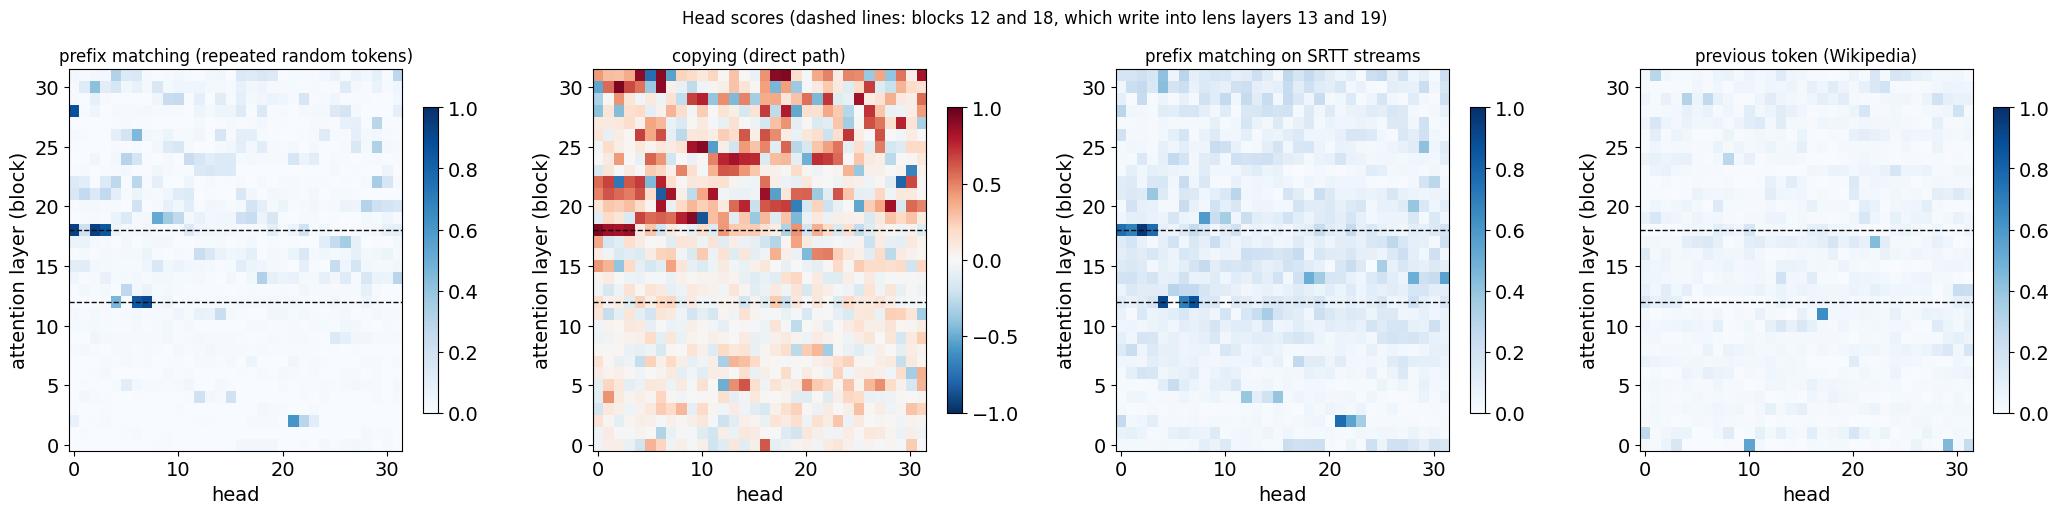

,block,head,prefix,copying,prefix on SRTT,previous token,induction (both thresholds)
rank,,,,,,,
1,18,0,0.932,0.929,0.756,0.001,True
2,18,2,0.934,0.827,0.971,0.004,True
3,18,3,0.851,0.858,0.766,0.002,True
4,19,8,0.522,0.776,0.578,0.011,True
5,30,2,0.416,0.945,0.253,0.005,True
6,19,9,0.364,0.917,0.222,0.004,True
7,26,6,0.452,0.643,0.170,0.006,False
8,31,4,0.315,0.892,0.409,0.014,True
9,20,28,0.308,0.838,0.393,0.017,True


correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = 0.77


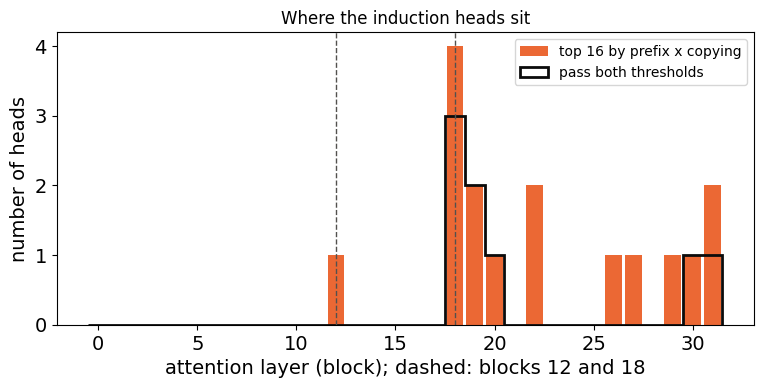

In [84]:
induction_rank_score = prefix_scores * np.clip(copy_scores, 0, None)
order = np.argsort(-induction_rank_score, axis=None)
ranked_heads = [tuple(int(v) for v in np.unravel_index(i, induction_rank_score.shape)) for i in order]
is_induction = (prefix_scores >= PREFIX_THRESHOLD) & (copy_scores >= COPY_THRESHOLD)
print(f"{int(is_induction.sum())} heads pass both thresholds (prefix >= {PREFIX_THRESHOLD}, copying >= {COPY_THRESHOLD})")


def plot_head_heatmaps(panels, title):
  fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.2), squeeze=False)
  for ax, (name, values, vmin, vmax, cmap) in zip(axes[0], panels):
    im = ax.imshow(values, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    for block in (12, 18):  # feed lens layers 13 and 19
      if block < NUM_LAYERS:
        ax.axhline(block, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("head")
    ax.set_ylabel("attention layer (block)")
    fig.colorbar(im, ax=ax, shrink=0.8)
  fig.suptitle(title)
  fig.tight_layout()
  plt.show()


plot_head_heatmaps([("prefix matching (repeated random tokens)", prefix_scores, 0, 1, 'Blues'),
                    ("copying (direct path)", copy_scores, -1, 1, 'RdBu_r'),
                    ("prefix matching on SRTT streams", srtt_prefix_scores, 0, 1, 'Blues'),
                    ("previous token (Wikipedia)", prev_token_scores, 0, 1, 'Blues')],
                   "Head scores (dashed lines: blocks 12 and 18, which write into lens layers 13 and 19)")

top30 = pd.DataFrame([{"rank": r + 1, "block": l, "head": h,
                       "prefix": prefix_scores[l, h], "copying": copy_scores[l, h],
                       "prefix on SRTT": srtt_prefix_scores[l, h], "previous token": prev_token_scores[l, h],
                       "induction (both thresholds)": bool(is_induction[l, h])}
                      for r, (l, h) in enumerate(ranked_heads[:30])]).set_index("rank")
display(top30.round(3))

corr = np.corrcoef(prefix_scores.ravel(), srtt_prefix_scores.ravel())[0, 1]
print(f"correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
layers_top = [l for l, _ in ranked_heads[:max(K_LIST)]]
ax.hist(layers_top, bins=np.arange(NUM_LAYERS + 1) - 0.5, color='#eb6834', rwidth=0.85,
        label=f"top {max(K_LIST)} by prefix x copying")
ax.hist(np.nonzero(is_induction)[0], bins=np.arange(NUM_LAYERS + 1) - 0.5, histtype='step', color='#0b0b0b',
        linewidth=2, label="pass both thresholds")
for block in (12, 18):  # feed lens layers 13 and 19
  ax.axvline(block, color='#52514e', linestyle='--', linewidth=1)
ax.set_xlabel("attention layer (block); dashed: blocks 12 and 18")
ax.set_ylabel("number of heads")
ax.set_title("Where the induction heads sit")
ax.legend()
plt.show()

In [85]:
def head_slice(h):
  return slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)


@contextmanager
def ablate_heads(model, heads, mode="mean", means=None):
  """Replaces the o_proj input slice of every (layer, head) in heads with its mean (or zero). Other heads untouched."""
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  handles = []
  for l, hs in by_layer.items():
    idx = torch.cat([torch.arange(h * HEAD_DIM, (h + 1) * HEAD_DIM) for h in hs])
    replacement = None if mode == "zero" else means[l][idx]

    def pre_hook(module, args, idx=idx, replacement=replacement):
      x = args[0].clone()
      idx_d = idx.to(x.device)
      x[..., idx_d] = 0 if replacement is None else replacement.to(device=x.device, dtype=x.dtype)
      return (x,) + tuple(args[1:])

    handles.append(model.model.layers[l].self_attn.o_proj.register_forward_pre_hook(pre_hook))
  try:
    yield
  finally:
    for handle in handles:
      handle.remove()


def compute_head_means():
  """Mean o_proj input per layer over Wikipedia text (train split; BOS position excluded)."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, MEAN_ABLATION_SEQS, TUNED_LENS_SEQ_LEN, "train")
  sums = torch.zeros(NUM_LAYERS, NUM_HEADS * HEAD_DIM, dtype=torch.float64)
  count = 0
  with torch.no_grad(), capture_heads(model, attention=False) as store:
    for start in range(0, len(tokens), WIKI_BATCH):
      model(input_ids=tokens[start:start + WIKI_BATCH].to(device), use_cache=False)
      for l in range(NUM_LAYERS):
        sums[l] += store["z"][l][:, 1:].double().sum(dim=(0, 1)).cpu()
      count += store["z"][0][:, 1:].shape[0] * store["z"][0][:, 1:].shape[1]
  return (sums / count).float().numpy()


head_means = torch.tensor(load_or_compute("head_means", compute_head_means))

# Sanity check: ablating one head changes only that head's slice of its layer's o_proj input.
check_layer, check_head = ranked_heads[0]
probe = load_lens_training_tokens(tokenizer, 1, 32, "validation").to(get_device())
with torch.no_grad():
  with capture_heads(model, attention=False) as clean:
    clean_logits = model(input_ids=probe, use_cache=False).logits.float()
  with ablate_heads(model, [(check_layer, check_head)], "mean", head_means), capture_heads(model, attention=False) as ablated:
    ablated_logits = model(input_ids=probe, use_cache=False).logits.float()
z_clean, z_abl = clean["z"][check_layer][0].float(), ablated["z"][check_layer][0].float()
inside = head_slice(check_head)
outside = torch.ones(z_clean.shape[-1], dtype=torch.bool)
outside[inside] = False
assert torch.allclose(z_clean[:, outside], z_abl[:, outside], atol=1e-3), "other heads in the layer changed"
assert torch.allclose(z_abl[:, inside], head_means[check_layer][inside].to(z_abl).expand_as(z_abl[:, inside]), atol=1e-2)
assert all(torch.allclose(clean["z"][l].float(), ablated["z"][l].float(), atol=1e-3) for l in range(check_layer)), "earlier layers changed"
print(f"[sanity] ablating layer {check_layer} head {check_head}: only its {HEAD_DIM} numbers changed in that layer; "
      f"output logits moved by up to {(clean_logits - ablated_logits).abs().max().item():.3f}")
del clean, ablated, clean_logits, ablated_logits

loaded head_means from /content/drive/MyDrive/plasticity_lens_cache/induction_heads/head_means_scores_mistral_trained_8bit_c8d03a42.npy
[sanity] ablating layer 18 head 0: only its 128 numbers changed in that layer; output logits moved by up to 1.172


In [86]:
K_MAX = max(K_LIST)
induction_sets = {k: ranked_heads[:k] for k in K_LIST}
excluded = set(ranked_heads[:K_MAX]) | {(int(l), int(h)) for l, h in zip(*np.nonzero(is_induction))}


def layer_matched_random_heads(reference, seed):
  """Random non-induction heads with the same number per layer as `reference`."""
  rng = np.random.default_rng(seed)
  per_layer = defaultdict(int)
  for l, _ in reference:
    per_layer[l] += 1
  chosen = []
  for l, n in sorted(per_layer.items()):
    pool = [h for h in range(NUM_HEADS) if (l, h) not in excluded]
    assert len(pool) >= n, f"layer {l}: only {len(pool)} non-induction heads for {n} needed"
    chosen += [(l, int(h)) for h in rng.choice(pool, size=n, replace=False)]
  return chosen


def per_layer_counts(heads):
  counts = defaultdict(int)
  for l, _ in heads:
    counts[l] += 1
  return dict(counts)


conditions = {"baseline": {"heads": [], "mode": "mean", "lens": True}}
for k in K_LIST:
  conditions[f"induction_top{k}"] = {"heads": induction_sets[k], "mode": "mean", "lens": k == K_MAX}
for d in range(N_RANDOM_DRAWS):
  heads = layer_matched_random_heads(induction_sets[K_MAX], seed=d)
  assert per_layer_counts(heads) == per_layer_counts(induction_sets[K_MAX])
  conditions[f"random{K_MAX}_draw{d}"] = {"heads": heads, "mode": "mean", "lens": False}
if RUN_ZERO_ABLATION:
  conditions[f"induction_top{K_MAX}_zero"] = {"heads": induction_sets[K_MAX], "mode": "zero", "lens": False}
if RUN_PREV_TOKEN_CONDITION:
  prev_order = np.argsort(-prev_token_scores, axis=None)
  prev_heads = [tuple(int(v) for v in np.unravel_index(i, prev_token_scores.shape)) for i in prev_order[:K_MAX]]
  conditions[f"prevtoken_top{K_MAX}"] = {"heads": prev_heads, "mode": "mean", "lens": False}

print(f"[sanity] random draws match the induction set's per-layer counts: {per_layer_counts(induction_sets[K_MAX])}")
print(pd.DataFrame([{"condition": name, "heads ablated": len(c["heads"]), "mode": c["mode"],
                     "per-layer lens": c["lens"]} for name, c in conditions.items()]).set_index("condition"))

[sanity] random draws match the induction set's per-layer counts: {18: 4, 19: 2, 30: 1, 26: 1, 31: 2, 20: 1, 27: 1, 22: 2, 12: 1, 29: 1}
                 heads ablated  mode  per-layer lens
condition                                           
baseline                     0  mean            True
induction_top4               4  mean           False
induction_top8               8  mean           False
induction_top16             16  mean            True
random16_draw0              16  mean           False
random16_draw1              16  mean           False


## Transitions

### In plain words
Every word in the grammar phase is produced by one transition: the grammar is in some **state**, and emits a word.
- **SRTT** has 9 transitions, one per position in the repeated sequence `0 1 2 2 0 2 3 1 END`. We label them by the
  previous word and the next word (e.g. `2→0`). A transition is **ambiguous for simple copying** if the previous word
  is followed by different words at different places in the sequence: after `2` can come `2`, `0` or `3`, so "copy
  what came after `2` last time" is not enough; only `3→1` and `END→0` are unique.
- **AGL** has 11 transitions, labelled by the state before the word and the word (e.g. `q1 → 3`). Every state has 2–3
  options, so all of them are probabilistic. The table below also shows, for each previous word, which states it can
  lead into: if it is more than one, the previous word alone does not tell the model where in the grammar it is.

**The measure:** the probability of the correct next word, averaged per transition over the last 1,000 grammar words
of each run (the same window as the learning score), final output.

In [87]:
SRTT_CYCLE = []
_state = "q0"
while True:  # walk the deterministic SRTT chain once: [(state, symbol), ...]
  (symbol, nxt), = srtt_transitions[_state].items()
  SRTT_CYCLE.append((_state, symbol))
  _state = nxt
  if _state == "q0":
    break
SRTT_SUCCESSORS = defaultdict(set)
for k, (_, symbol) in enumerate(SRTT_CYCLE):
  SRTT_SUCCESSORS[SRTT_CYCLE[k - 1][1]].add(symbol)
SRTT_ORDER = [f"{SRTT_CYCLE[k - 1][1]}→{symbol}" for k, (_, symbol) in enumerate(SRTT_CYCLE)]
SRTT_AMBIGUOUS = {f"{SRTT_CYCLE[k - 1][1]}→{symbol}": len(SRTT_SUCCESSORS[SRTT_CYCLE[k - 1][1]]) > 1
                  for k, (_, symbol) in enumerate(SRTT_CYCLE)}
AGL_ORDER = [f"{state} → {symbol}" for state in agl_transitions for symbol in agl_transitions[state]]
LEADS_INTO = defaultdict(set)  # AGL: previous word -> states it can lead into
for state, edges in agl_transitions.items():
  for symbol, nxt in edges.items():
    LEADS_INTO[symbol].add(nxt)
TRANSITION_ORDER = {"AGL": AGL_ORDER, "SRTT": SRTT_ORDER}


def transition_labels(p, grammar):
  """Label of the transition that produces each grammar-phase word t (prompt index)."""
  lb, le = p["learning_begins"], p["learning_ends"]
  states, symbols = p["structure_state_sequences"], p["placeholder_prompt"]
  if grammar == "SRTT":
    return {t: f"{symbols[t - 1]}→{symbols[t]}" for t in range(lb, le)}
  return {t: f"{states[t - lb]} → {symbols[t]}" for t in range(lb, le)}


def per_transition_probs(lens_results, prompts, grammar, last_n=LAST_N_STRUCTURED):
  """(runs x transitions) mean probability of the correct next word, final output, last `last_n` grammar words."""
  rows = []
  for r, p in zip(lens_results, prompts):
    probs = lens_next_token_probs(r, renormalize=False)[-1]
    labels = transition_labels(p, grammar)
    acc = defaultdict(list)
    for t in range(p["learning_ends"] - last_n, p["learning_ends"]):
      acc[labels[t]].append(probs[t])
    rows.append({k: np.mean(v) for k, v in acc.items()})
  return pd.DataFrame(rows)[[k for k in TRANSITION_ORDER[grammar] if k in rows[0]]]


def paired_change(condition_df, baseline_df):
  """Per-run difference from baseline, per transition: mean and standard error (negative = worse)."""
  diff = condition_df.values - baseline_df.values
  n = diff.shape[0]
  return (pd.Series(diff.mean(0), index=baseline_df.columns),
          pd.Series(diff.std(0, ddof=1) / np.sqrt(n) if n > 1 else np.zeros(diff.shape[1]), index=baseline_df.columns))


def specialization_index(mean_change):
  """How concentrated the damage is across transitions: 0 = spread evenly, 1 = all on one transition.
  Uses drops only (negative changes); NaN when there is no drop at all."""
  drops = np.clip(-np.asarray(mean_change, dtype=float), 0, None)
  k, total = len(drops), drops.sum()
  return np.nan if total <= 0 else (drops.max() / total - 1 / k) / (1 - 1 / k)


display(pd.DataFrame({"SRTT transition": SRTT_ORDER,
                      "ambiguous for simple copying": [SRTT_AMBIGUOUS[k] for k in SRTT_ORDER],
                      "previous word can be followed by": [", ".join(sorted(SRTT_SUCCESSORS[k.split("→")[0]])) for k in SRTT_ORDER]}).set_index("SRTT transition"))
display(pd.DataFrame({"AGL: previous word": sorted(LEADS_INTO),
                      "states it can lead into": [", ".join(sorted(LEADS_INTO[w])) for w in sorted(LEADS_INTO)],
                      "identifies the state alone": [len(LEADS_INTO[w]) == 1 for w in sorted(LEADS_INTO)]}).set_index("AGL: previous word"))

,ambiguous for simple copying,previous word can be followed by
SRTT transition,,
END→0,False,0
0→1,True,"1, 2"
1→2,True,"2, END"
2→2,True,"0, 2, 3"
2→0,True,"0, 2, 3"
0→2,True,"1, 2"
2→3,True,"0, 2, 3"
3→1,False,1
1→END,True,"2, END"


,states it can lead into,identifies the state alone
AGL: previous word,,
0,"q0, q3",False
1,"q0, q1",False
2,"q0, q4",False
3,"q0, q2",False
END,q0,True


## Settings for this notebook

`N_RUNS_TM` runs per grammar (the first 10 of the same streams), used in every condition, so every result is a paired
per-run difference from no knockout.

In [88]:
N_RUNS_TM = 10                        # runs per grammar in every condition (paired)
GROUP_HEADS = induction_sets[K_MAX]    # the top-16 induction heads (same as in 03/05)
RANDOM_GROUP_HEADS = conditions[f"random{K_MAX}_draw0"]["heads"]  # 16 random layer-matched heads (same as in 03/05)
SINGLE_HEADS = [(18, 0), (18, 1), (18, 2), (18, 3)]               # the block-18 heads, one at a time
READING_RUNS = 5                      # Step 1: runs per grammar
READING_QUERIES = 400                 # Step 1: query positions per run (last LAST_N_STRUCTURED grammar words)
RECENCY_K = 10                        # Step 1: recency profile over the 10 most recent earlier occurrences
SIGNIFICANT_SE = 3

TM_DIR = os.path.join(LENS_CACHE_DIR, "transition_memory") if LENS_CACHE_DIR else None
if TM_DIR:
  os.makedirs(TM_DIR, exist_ok=True)
tm_prompts = {"AGL": agl_prompts[:N_RUNS_TM], "SRTT": srtt_prompts[:N_RUNS_TM]}
SINGLE_HEADS = [h for h in SINGLE_HEADS if h[0] < NUM_LAYERS and h[1] < NUM_HEADS]
print(f"group of {len(GROUP_HEADS)}: {GROUP_HEADS}")
print(f"random control group: {RANDOM_GROUP_HEADS}")
print(f"single heads: {SINGLE_HEADS}")

group of 16: [(18, 0), (18, 2), (18, 3), (19, 8), (30, 2), (19, 9), (26, 6), (31, 4), (20, 28), (31, 31), (27, 29), (22, 6), (12, 7), (22, 4), (29, 10), (18, 1)]
random control group: [(12, 27), (18, 17), (18, 11), (18, 12), (18, 19), (19, 5), (19, 26), (20, 29), (22, 16), (22, 20), (26, 23), (27, 19), (29, 17), (30, 18), (31, 28), (31, 9)]
single heads: [(18, 0), (18, 1), (18, 2), (18, 3)]


## The attention knockout

### In plain words
In each selected head we can forbid attention from a word to a chosen set of earlier words: those links get exactly
zero attention, and the head spreads its attention over the remaining earlier words as usual. All other heads, and all
layers without a selected head, run unchanged.

**Which words are blocked** is decided per run from the stream itself: e.g. "every earlier word that was produced by
transition `q1 → 3`". The blocked set always lies strictly in the past: a word never loses access to itself (or to the
start token), only to earlier words.

**Sanity checks** printed below: with nothing blocked, the custom attention reproduces the model's normal output up to
rounding (and every condition is compared with a no-block run through this same custom attention, so even that cancels);
blocked links get exactly zero attention in the selected heads, and the other heads are untouched; and every blocked
word in a transition knockout really is the word that transition produces.

In [89]:
try:
  from transformers import AttentionInterface
  from transformers.integrations.sdpa_attention import sdpa_attention_forward
except ImportError as error:
  raise ImportError("this notebook needs transformers >= 4.48 (custom attention functions): run "
                    "!pip install -q -U transformers, then Runtime -> Restart session") from error

_ko = {"layers": {}, "mask": None, "callback": None, "callback_heads": {}, "builder": None}


def knockout_attention(module, query, key, value, attention_mask, scaling=None, dropout=0.0, **kwargs):
  """Attention with per-head link blocking. query (B, H, T, D); key/value (B, KV, T, D); returns (B, T, H, D).
  Every head first runs the normal (sdpa) attention. Each selected head is then recomputed on its own, in float32,
  with its blocked links set to -inf before the softmax, and its output replaced. One head at a time keeps the
  memory to a single (T, T) table (~64 MB for 4,000 tokens) instead of all 32 heads at once (~2 GB per copy)."""
  out, weights = sdpa_attention_forward(module, query, key, value, attention_mask, scaling=scaling, dropout=dropout, **kwargs)
  layer = getattr(module, "layer_idx", None)
  heads = _ko["layers"].get(layer, [])
  watched = _ko["callback_heads"].get(layer, []) if _ko["callback"] is not None else []
  if not heads and not watched:
    return out, weights
  assert query.shape[0] == 1 and query.shape[2] == key.shape[2], "knockout expects one sequence, no KV cache"
  n_rep = query.shape[1] // key.shape[1]
  scale = scaling if scaling is not None else query.shape[-1] ** -0.5
  T = query.shape[2]
  causal = torch.ones(T, T, dtype=torch.bool, device=query.device).triu(1)
  blocked = causal if _ko["mask"] is None else causal | _ko["mask"]
  for h in sorted(set(heads) | set(watched)):
    kv = h // n_rep
    scores = (query[0, h].float() @ key[0, kv].float().T) * scale  # (T, T)
    probs = torch.softmax(scores.masked_fill_(blocked if h in heads else causal, float("-inf")), dim=-1)
    del scores
    if h in watched:
      _ko["callback"](layer, h, probs)
    if h in heads:
      out[0, :, h] = (probs @ value[0, kv].float()).to(out.dtype)
    del probs
  return out, weights


AttentionInterface.register("knockout", knockout_attention)


def _set_mask_from_input(module, args, kwargs):
  ids = kwargs.get("input_ids", args[0] if args else None)
  if _ko["builder"] is not None:
    key = hashlib.md5(ids[0].cpu().numpy().tobytes()).hexdigest()
    mask = _ko["builder"](key)
    _ko["mask"] = None if mask is None else mask.to(ids.device)


@contextmanager
def knockout(heads, builder):
  """heads: [(layer, head)] whose attention is blocked; builder(input_key) -> (T, T) bool mask (True = blocked)
  or None. The mask is built per run from that run's stream."""
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  _ko.update(layers=dict(by_layer), builder=builder, mask=None)
  set_attention_implementation(model, "knockout")
  handle = model.register_forward_pre_hook(_set_mask_from_input, with_kwargs=True)
  try:
    yield
  finally:
    handle.remove()
    _ko.update(layers={}, builder=None, mask=None)
    set_attention_implementation(model, "sdpa")


# ---- per-run stream bookkeeping: input key -> prompt, transition label of every grammar word
def input_key(prompt):
  return hashlib.md5(prepare_lens_inputs(tokenizer, prompt)["input_ids"][0].numpy().tobytes()).hexdigest()


def stream_info(prompt, grammar):
  """Input length, grammar-phase bounds, and for every prompt index u in the grammar phase its transition label.
  Prompt word u sits at input position u + 1 (BOS first)."""
  lb, le = prompt["learning_begins"], prompt["learning_ends"]
  labels = transition_labels(prompt, grammar)
  return {"T": len(prompt["mapped_prompt"]) + 1, "lb": lb, "le": le, "labels": labels,
          "positions": {S: np.array([u + 1 for u in range(lb, le) if labels[u] == S]) for S in TRANSITION_ORDER[grammar]}}


def mask_block_source(info, S):
  """Block, for every query, the earlier words produced by transition S."""
  mask = torch.zeros(info["T"], info["T"], dtype=torch.bool)
  mask[:, torch.as_tensor(info["positions"][S], dtype=torch.long)] = True
  return mask.fill_diagonal_(False)  # a word always keeps access to itself: only strictly earlier words are blocked


def mask_block_random(info, S, seed):
  """Control: block as many random grammar-phase words as transition S has, chosen among the other transitions' words."""
  others = np.concatenate([p for s, p in info["positions"].items() if s != S])
  rng = np.random.default_rng(seed)
  chosen = rng.choice(others, size=min(len(info["positions"][S]), len(others)), replace=False)
  mask = torch.zeros(info["T"], info["T"], dtype=torch.bool)
  mask[:, torch.as_tensor(chosen, dtype=torch.long)] = True
  return mask.fill_diagonal_(False)


def mask_same_transition(info, mode, seed=0):
  """Query-specific masks for Step 3. For a query at input position t (it predicts prompt word t, produced by
  transition T), block among the earlier words produced by T: 'recent' = only the most recent one, 'older' = all but
  the most recent, 'all' = all of them; 'random' = as many random earlier grammar-phase words of other transitions."""
  mask = torch.zeros(info["T"], info["T"], dtype=torch.bool)
  rng = np.random.default_rng(seed)
  for t in range(info["lb"], info["le"]):
    same = info["positions"].get(info["labels"][t], np.array([], dtype=int))  # (first SRTT word: label from the random part)
    same = same[same < t]  # strictly earlier occurrences: input position t is the query's own word
    if len(same) == 0:
      continue
    if mode == "recent":
      cols = same[-1:]
    elif mode == "older":
      cols = same[:-1]
    elif mode == "all":
      cols = same
    else:
      pool = np.setdiff1d(np.arange(info["lb"] + 1, t), same)
      cols = rng.choice(pool, size=min(len(same), len(pool)), replace=False) if len(pool) else pool
    if len(cols):
      mask[t, torch.as_tensor(cols, dtype=torch.long)] = True
  return mask


# ---- sanity checks
_p = tm_prompts["AGL"][0]
_info = stream_info(_p, "AGL")
_ids = prepare_lens_inputs(tokenizer, _p)["input_ids"]
_S = TRANSITION_ORDER["AGL"][2]
_mask = mask_block_source(_info, _S)
_symbol = _S.split(" → ")[1]
_cands = prepare_lens_inputs(tokenizer, _p)["cand_ids"]  # the 4 words in vocabulary order (= symbols 0..3), END last
_word_id = _cands[-1] if _symbol == SEP_TOKEN else _cands[int(_symbol)]
assert all(_ids[0, c].item() == _word_id for c in _info["positions"][_S]), "blocked words must be the word transition S produces"
with torch.no_grad():
  device = get_device()
  probe_layer, probe_head = GROUP_HEADS[0]
  captured, z = [], []
  _hook = model.model.layers[probe_layer].self_attn.o_proj.register_forward_pre_hook(
    lambda module, args: z.append(args[0][0].detach().float().cpu()))  # every head's output in that layer
  try:
    clean = model(input_ids=_ids.to(device), use_cache=False).logits[0].float().cpu()             # z[0]: normal
    with knockout([(probe_layer, probe_head)], lambda key: None):                                  # z[1]: recomputed, nothing blocked
      model(input_ids=_ids.to(device), use_cache=False)
    _ko.update(callback=lambda layer, h, probs: captured.append(probs.detach().cpu()), callback_heads={probe_layer: [probe_head]})
    with knockout([(probe_layer, probe_head)], lambda key: _mask):                                 # z[2]: blocked
      blocked_logits = model(input_ids=_ids.to(device), use_cache=False).logits[0].float().cpu()
    _ko.update(callback=None, callback_heads={})
    with knockout(GROUP_HEADS, lambda key: None):  # all 16 group heads recomputed, nothing blocked     # z[3]
      same = model(input_ids=_ids.to(device), use_cache=False).logits[0].float().cpu()
  finally:
    _hook.remove()
    _ko.update(callback=None, callback_heads={})
probs_blocked = captured[0]
cols = torch.as_tensor(_info["positions"][_S], dtype=torch.long)
probe_slice = slice(probe_head * HEAD_DIM, (probe_head + 1) * HEAD_DIM)
other_cols = torch.ones(z[0].shape[-1], dtype=torch.bool)
other_cols[probe_slice] = False

# 1) The recomputed head itself equals the normal attention of that head (same inputs, so only rounding differs).
head_rel_err = ((z[1][:, probe_slice] - z[0][:, probe_slice]).abs().max() / z[0][:, probe_slice].abs().max()).item()
print(f"[sanity] head {probe_layer}.{probe_head} recomputed (nothing blocked) vs. normal attention: relative error "
      f"{head_rel_err:.1e}; other heads of the layer identical: {torch.equal(z[0][:, other_cols], z[1][:, other_cols])}")
assert head_rel_err < 1e-2, "the recomputed head must match the normal attention"
assert torch.equal(z[0][:, other_cols], z[1][:, other_cols]), "other heads must be untouched"
# 2) All 16 recomputed: the output moves only by rounding, amplified through the later (8-bit) layers. Not a bias in
#    the results: every condition is compared with a no-block baseline that goes through this same path.
logit_diff = (clean - same).abs()
prob_diff = (torch.softmax(clean, -1) - torch.softmax(same, -1)).abs().max(-1).values
print(f"[sanity] all 16 group heads recomputed, nothing blocked, vs. normal: |logit diff| mean {logit_diff.mean().item():.1e}, "
      f"max {logit_diff.max().item():.2f}; next-word probability diff: median {prob_diff.median().item():.1e}, "
      f"max {prob_diff.max().item():.3f} (rounding; it cancels against the no-block baseline)")
assert logit_diff.mean().item() < 0.1, "recomputing the heads without blocking must leave the output (nearly) unchanged"
# 3) Blocking: exactly zero attention on the blocked links, only that head's output changes.
assert not _mask.diagonal().any(), "a word must never be blocked from itself"
assert probs_blocked[_mask].abs().max().item() == 0, "blocked links must get zero attention"
assert torch.equal(z[0][:, other_cols], z[2][:, other_cols]), "other heads must be untouched"
assert not torch.equal(z[1][:, probe_slice], z[2][:, probe_slice]), "the blocked head's output must change"
print(f"[sanity] blocking '{_S}' in head {probe_layer}.{probe_head}: zero attention on its {len(cols)} words, other heads "
      f"untouched, every blocked word is that transition's word; output moved by up to {(blocked_logits - clean).abs().max().item():.2f}")
del clean, same, blocked_logits, captured, z, probs_blocked, logit_diff, prob_diff
if device == 'cuda':
  torch.cuda.empty_cache()

[sanity] head 18.0 recomputed (nothing blocked) vs. normal attention: relative error 3.8e-03; other heads of the layer identical: True
[sanity] all 16 group heads recomputed, nothing blocked, vs. normal: |logit diff| mean 3.8e-02, max 0.55; next-word probability diff: median 1.1e-02, max 0.059 (rounding; it cancels against the no-block baseline)
[sanity] blocking 'q1 → 3' in head 18.0: zero attention on its 235 words, other heads untouched, every blocked word is that transition's word; output moved by up to 0.56


## Settings for this notebook, and shared tools

`VAL_RUNS` = the 20 streams per grammar used in `05` (run 2). The no-switch-off, top-16-off, random-16-off and
leave-one-in results for these streams are on Drive and load in seconds. New conditions run on the same 20 streams, so
every comparison is **paired** (same stream, with and without the change).

Shared statistics used below:
- **95% bootstrap interval** of a mean: resample the runs 10,000 times.
- **Sign-flip test** for a paired difference: flip the sign of each run's difference at random, 10,000 times.
- **Benjamini–Hochberg FDR:** among many cells tested at once, keep the false-discovery rate at 5%.

In [90]:
from scipy import stats
import gc

N_RUNS_P1 = 20                 # Part 1: runs per grammar for the all-layer logit + tuned lens pass
VAL_RUNS = 20                  # Parts 2-3: the 20 streams of 05 (run 2), paired with the results saved there
N_BOOT = 10000                 # bootstrap resamples / sign flips
FDR_Q = 0.05                   # Benjamini-Hochberg false-discovery rate
JUMP_LAYER = 19                # the layer we expect the largest one-layer increase at
RAW_TABLE_LAYERS = [0, 13, 18, 19, 24, 32]
OLSSON_RERUN_MIN_DIFF = 4      # Part 2: rerun the ablation for the threshold set if it differs from the top 16 by more heads
CONTROL_BLOCKS = (18, 19)      # Part 3: random non-induction control heads come from these blocks ...
N_CONTROL_HEADS = 4            # ... this many, split evenly over the blocks
N_PERMUTATIONS_MAP = 100       # Part 3a: label shuffles per run for the reading-map permutation baseline
NOISE_BEFORE = [15, 16, 17, 18]  # Part 3d: lens layers just before the jump ...
NOISE_AFTER = [19, 20, 21, 22]   # ... and just after it
NOISE_ALPHAS = [0.05, 0.1, 0.2, 0.4, 0.8]  # the noise sizes of 04 (their Wikipedia damage is reused from Drive)
DAMAGE_LEVEL = 0.05            # nats of extra Wikipedia loss at which layers are compared (as in 04)
NOISE_WIKI_SEQS = 25           # as in 04 (the saved Wikipedia losses use this number in their file names)
NOISE_WIKI_BATCH = 5
NOISE_GRAMMARS = ("AGL", "SRTT")

VAL_DIR = os.path.join(LENS_CACHE_DIR, "metric_validation") if LENS_CACHE_DIR else None
NOISE_DIR = os.path.join(LENS_CACHE_DIR, "noise_robustness") if LENS_CACHE_DIR else None
for d in (VAL_DIR, NOISE_DIR, os.path.join(LENS_CACHE_DIR, "head_specialization") if LENS_CACHE_DIR else None):
  if d:
    os.makedirs(d, exist_ok=True)
val_prompts = {"AGL": agl_prompts[:VAL_RUNS], "SRTT": srtt_prompts[:VAL_RUNS]}
RAW_TABLE_LAYERS = [L for L in RAW_TABLE_LAYERS if L <= NUM_LAYERS]
NOISE_BEFORE = [L for L in NOISE_BEFORE if 1 <= L < NUM_LAYERS]
NOISE_AFTER = [L for L in NOISE_AFTER if 1 <= L < NUM_LAYERS]


def per_run_scores(curves, prompts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per run and layer: the raw phase mean (last last_n grammar words), the raw baseline (first random part after the
  warm-up), the bound, and three scores: normalized (our learning score), difference (phase - baseline), ratio
  (phase / baseline). Same windows as lens_phase_summary. Arrays are (runs, layers); bound is (runs,)."""
  out = {k: [] for k in ("phase", "baseline", "bound", "normalized", "difference", "ratio")}
  for curve, p in zip(curves, prompts):
    lb, le = p["learning_begins"], p["learning_ends"]
    baseline = curve[:, warmup:lb].mean(axis=1)
    phase = curve[:, le - last_n:le].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    for k, v in (("phase", phase), ("baseline", baseline), ("bound", bound), ("normalized", (phase - baseline) / (bound - baseline)),
                 ("difference", phase - baseline), ("ratio", phase / baseline)):
      out[k].append(v)
  return {k: np.array(v) for k, v in out.items()}


def final_learning(lens_results, prompts):
  """Per-run learning score at the model's output (full vocabulary), as in 03-07."""
  curves = [lens_next_token_probs(r, renormalize=False)[-1:] for r in lens_results]
  return per_run_scores(curves, prompts)["normalized"][:, 0]


def mean_ci(x, seed=0):
  x = np.asarray(x, dtype=float)
  rng = np.random.default_rng(seed)
  boots = x[rng.integers(0, len(x), (N_BOOT, len(x)))].mean(1)
  return x.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


def sign_flip_p(x, seed=0):
  """Two-sided paired test of mean(x) = 0 by random sign flips."""
  x = np.asarray(x, dtype=float)
  rng = np.random.default_rng(seed)
  flips = rng.choice([-1.0, 1.0], size=(N_BOOT, len(x)))
  null = np.abs((flips * x).mean(1))
  return (1 + np.sum(null >= abs(x.mean()) - 1e-15)) / (1 + N_BOOT)


def bh_qvalues(pvals):
  """Benjamini-Hochberg q-values, same shape as pvals."""
  p = np.asarray(pvals, dtype=float).ravel()
  order = np.argsort(p)
  ranked = p[order] * len(p) / np.arange(1, len(p) + 1)
  q = np.minimum.accumulate(ranked[::-1])[::-1]
  out = np.empty_like(p)
  out[order] = np.minimum(q, 1)
  return out.reshape(np.shape(pvals))


def cell_pvalues(diff):
  """diff: (runs, ...) paired differences -> two-sided one-sample t-test p per cell (1 where the difference is
  identically zero)."""
  with np.errstate(all='ignore'):
    p = stats.ttest_1samp(diff, 0.0, axis=0).pvalue
  return np.where(np.isfinite(p), p, 1.0)


def cond05_cache_name(name, heads, grammar):
  """File names of 05 (run 2), so its saved switch-off results are reused."""
  digest = hashlib.md5(f"{sorted(heads)}|mean".encode()).hexdigest()[:8]
  return f"head_specialization/{lens_cache_name(grammar.lower())}_{name}_{digest}_n{VAL_RUNS}"


def run05(name, heads, grammar):
  """A switch-off condition on the VAL_RUNS streams: loaded from Drive when saved (05 or earlier sessions), else run."""
  with ablate_heads(model, heads, "mean", head_means):
    return run_lens_extraction(model, tokenizer, val_prompts[grammar], [NUM_LAYERS],
                               cache_name=cond05_cache_name(name, heads, grammar))["logit"]


def load_only(cache_name, prompts, keys=("logit",)):
  """Loads saved results for these prompts (or for the first len(prompts) of a longer saved list) without running
  anything. Returns ({key: [results]}, message); None when missing or computed on different streams."""
  path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if LENS_CACHE_DIR else None
  if not path or not os.path.exists(path):
    return None, f"not found: {cache_name}"
  with open(path, 'rb') as f:
    saved = pickle.load(f)
  if not all(k in saved for k in keys) or len(saved[keys[0]]) < len(prompts):
    return None, f"incomplete: {cache_name}"
  for r, p in zip(saved[keys[0]], prompts):
    if not np.array_equal(r["input_ids"], prepare_lens_inputs(tokenizer, p)["input_ids"][0].numpy()):
      return None, f"computed on different streams: {cache_name}"
  return {k: saved[k][:len(prompts)] for k in keys}, "ok"


probe_inputs = prepare_lens_inputs(tokenizer, val_prompts["AGL"][0])
started = time.time()
extract_lens_logprobs(model, probe_inputs, [NUM_LAYERS])
seconds_per_run = time.time() - started
noise_runs = len(NOISE_BEFORE + NOISE_AFTER) * len(NOISE_GRAMMARS) * VAL_RUNS
print(f"{seconds_per_run:.1f} s per run (final output). Upper estimates, before anything is loaded from Drive:\n"
      f"  Part 1: {2 * N_RUNS_P1 * 3.0 * seconds_per_run / 60:.0f} min (all layers, both lenses)\n"
      f"  Part 2: ~5 min (+ {2 * VAL_RUNS * seconds_per_run / 60:.0f} min if the threshold set needs its own ablation)\n"
      f"  Part 3a: ~{2 * READING_RUNS * 2 * seconds_per_run / 60 + 5:.0f} min; Part 3b: {N_CONTROL_HEADS * 2 * VAL_RUNS * seconds_per_run / 60:.0f} min; "
      f"Part 3c: ~0 min; Part 3d: {noise_runs * seconds_per_run / 60 + 10:.0f} min")

12.3 s per run (final output). Upper estimates, before anything is loaded from Drive:
  Part 1: 25 min (all layers, both lenses)
  Part 2: ~5 min (+ 8 min if the threshold set needs its own ablation)
  Part 3a: ~9 min; Part 3b: 33 min; Part 3c: ~0 min; Part 3d: 76 min


## Part 1: learning score vs. raw numbers

### In plain words
Our learning score divides by the room for improvement: (phase mean − baseline) ÷ (bound − baseline). Each part:
- **phase mean:** mean probability of the correct next word over the last 1,000 grammar words;
- **baseline:** the same over the first random part, after 50 warm-up words;
- **bound:** the best possible for that stream.

A division can create or hide a jump: if the baseline changes from one layer to the next, the score can jump even
when the phase mean does not. So, per layer, both lenses (logit, tuned), both ways of reading a layer (full
vocabulary, renormalized over the 5 candidates) and both grammars, we show:
- the **raw** phase mean and the raw baseline (± SE over runs);
- our normalized score;
- two alternatives: **difference** (phase mean − baseline, no division) and **ratio** (phase mean ÷ baseline).

The table lists, for every version, the layer with the **largest one-layer increase** (expected: 19 everywhere), and
the share of single runs whose largest increase is at 19. A second table gives the raw numbers at layers 0, 13, 18,
19, 24 and 32.

The `02` lens results on Drive were computed before the stream fix (2026-11-09) and do not match today's streams, so
the lens pass is redone on 20 runs per grammar. One pass gives both lenses; the tuned lens itself loads from Drive.

In [91]:
tuned_lens = load_or_train_tuned_lens(model, tokenizer).cpu()  # the translators wait on the CPU (GPU memory for the pass)
gc.collect()
if torch.cuda.is_available():
  torch.cuda.empty_cache()
p1_prompts = {"AGL": output["shuffle"][:N_RUNS_P1], "SRTT": output_srtt[:N_RUNS_P1]}
p1_results = {}
for grammar in ("AGL", "SRTT"):
  key = grammar.lower()
  saved, message = load_only(f"{lens_cache_name(key)}_{tuned_lens_cache_tag()}", p1_prompts[grammar], keys=("logit", "tuned"))
  print(f"[{grammar}] lens results of 02: {message}")
  if saved is None:
    saved = run_lens_extraction(model, tokenizer, p1_prompts[grammar], LAYERS_TO_DECODE, tuned_lens=tuned_lens,
                                cache_name=f"metric_validation/{lens_cache_name(key)}_{tuned_lens_cache_tag()}_n{N_RUNS_P1}")
  p1_results[grammar] = saved
layer_ids = p1_results["AGL"]["logit"][0]["layers"]

LENSES, METRICS, VERSIONS = ("logit", "tuned"), ("full vocabulary", "renormalized"), ("phase", "normalized", "difference", "ratio")
p1 = {}  # (lens, metric, grammar) -> per-run score arrays
for lens in LENSES:
  for metric in METRICS:
    for grammar in ("AGL", "SRTT"):
      curves = [lens_next_token_probs(r, renormalize=(metric == "renormalized")) for r in p1_results[grammar][lens]]
      p1[(lens, metric, grammar)] = per_run_scores(curves, p1_prompts[grammar])
      reference = lens_phase_summary(curves, p1_prompts[grammar])
      assert np.allclose(p1[(lens, metric, grammar)]["normalized"].mean(0), reference["norm_structured"].to_numpy()), \
        "per_run_scores must reproduce lens_phase_summary"
for r_logit, r_tuned in zip(p1_results["AGL"]["logit"], p1_results["AGL"]["tuned"]):
  assert np.array_equal(r_logit["logprobs"][-1], r_tuned["logprobs"][-1]), "both lenses must share the last layer"
print(f"[sanity] per-run scores reproduce lens_phase_summary for every lens, metric and grammar ({len(layer_ids)} layers)")

loaded tuned lens from /content/drive/MyDrive/plasticity_lens_cache/tuned_lens_lens_mistral_trained_8bit_tuned400x2x512p128.pt
[AGL] lens results of 02: not found: agl_mistral_trained_8bit_tuned400x2x512p128
loaded 20 runs (logit + tuned lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_tuned400x2x512p128_n20.pkl
[SRTT] lens results of 02: not found: srtt_mistral_trained_8bit_tuned400x2x512p128
loaded 20 runs (logit + tuned lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/srtt_mistral_trained_8bit_tuned400x2x512p128_n20.pkl
[sanity] per-run scores reproduce lens_phase_summary for every lens, metric and grammar (33 layers)


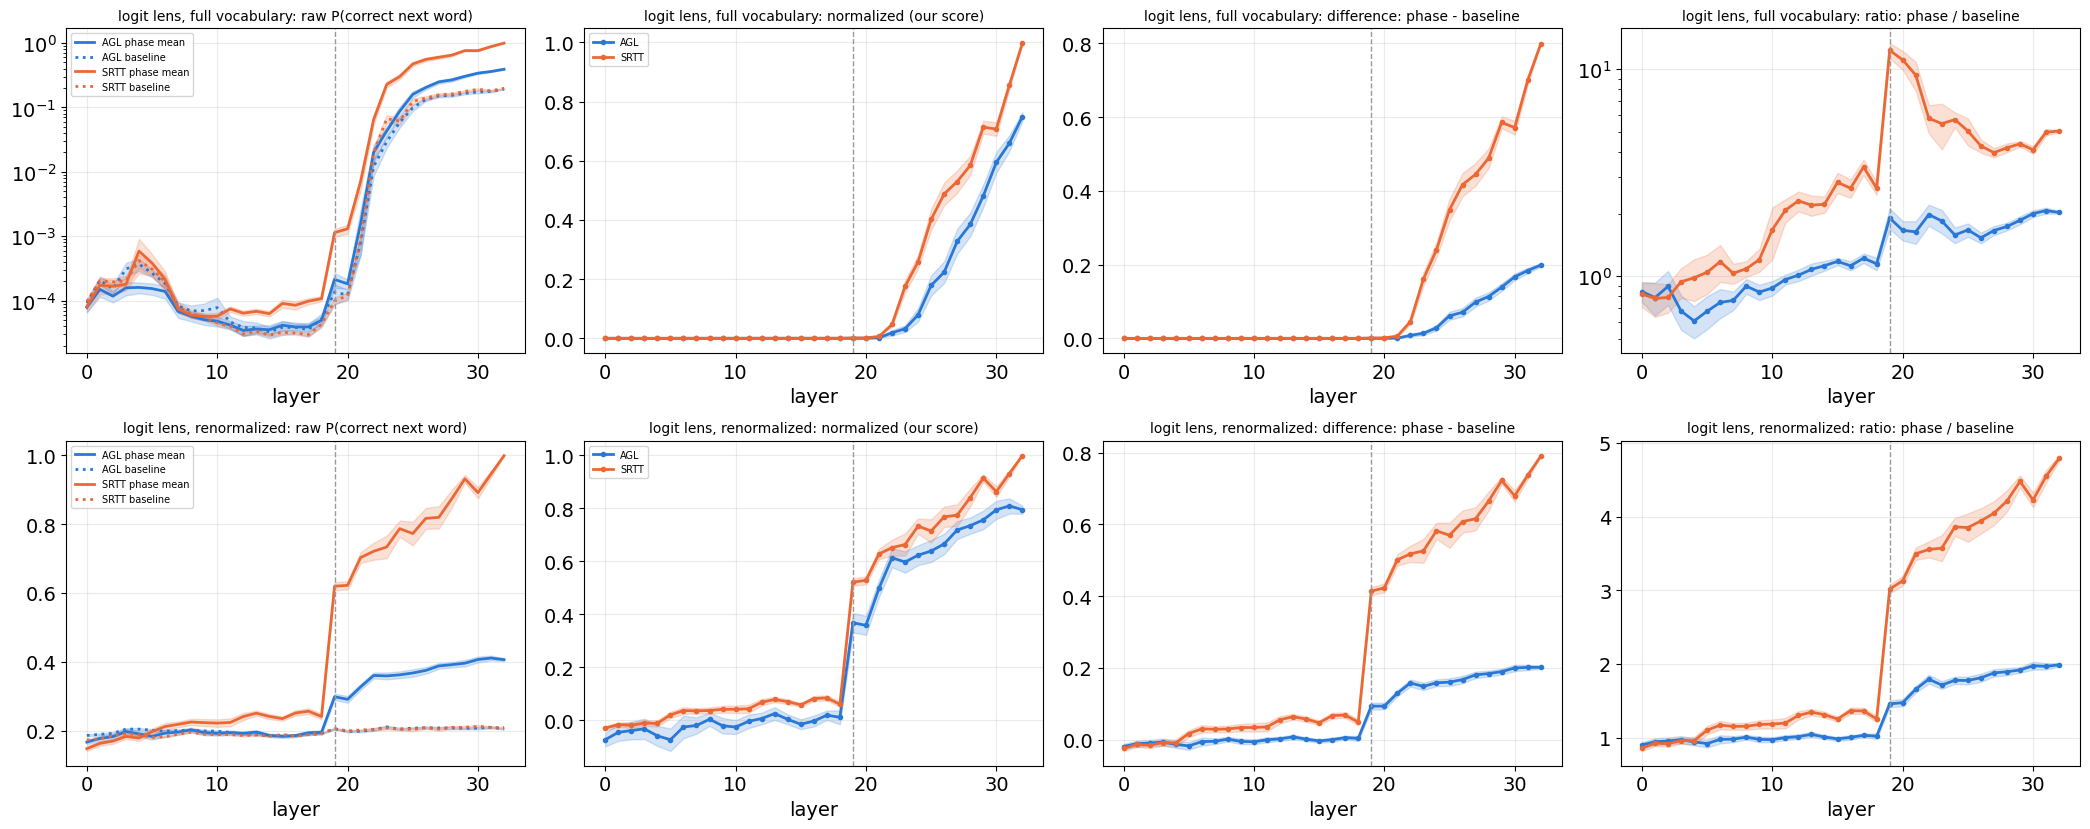

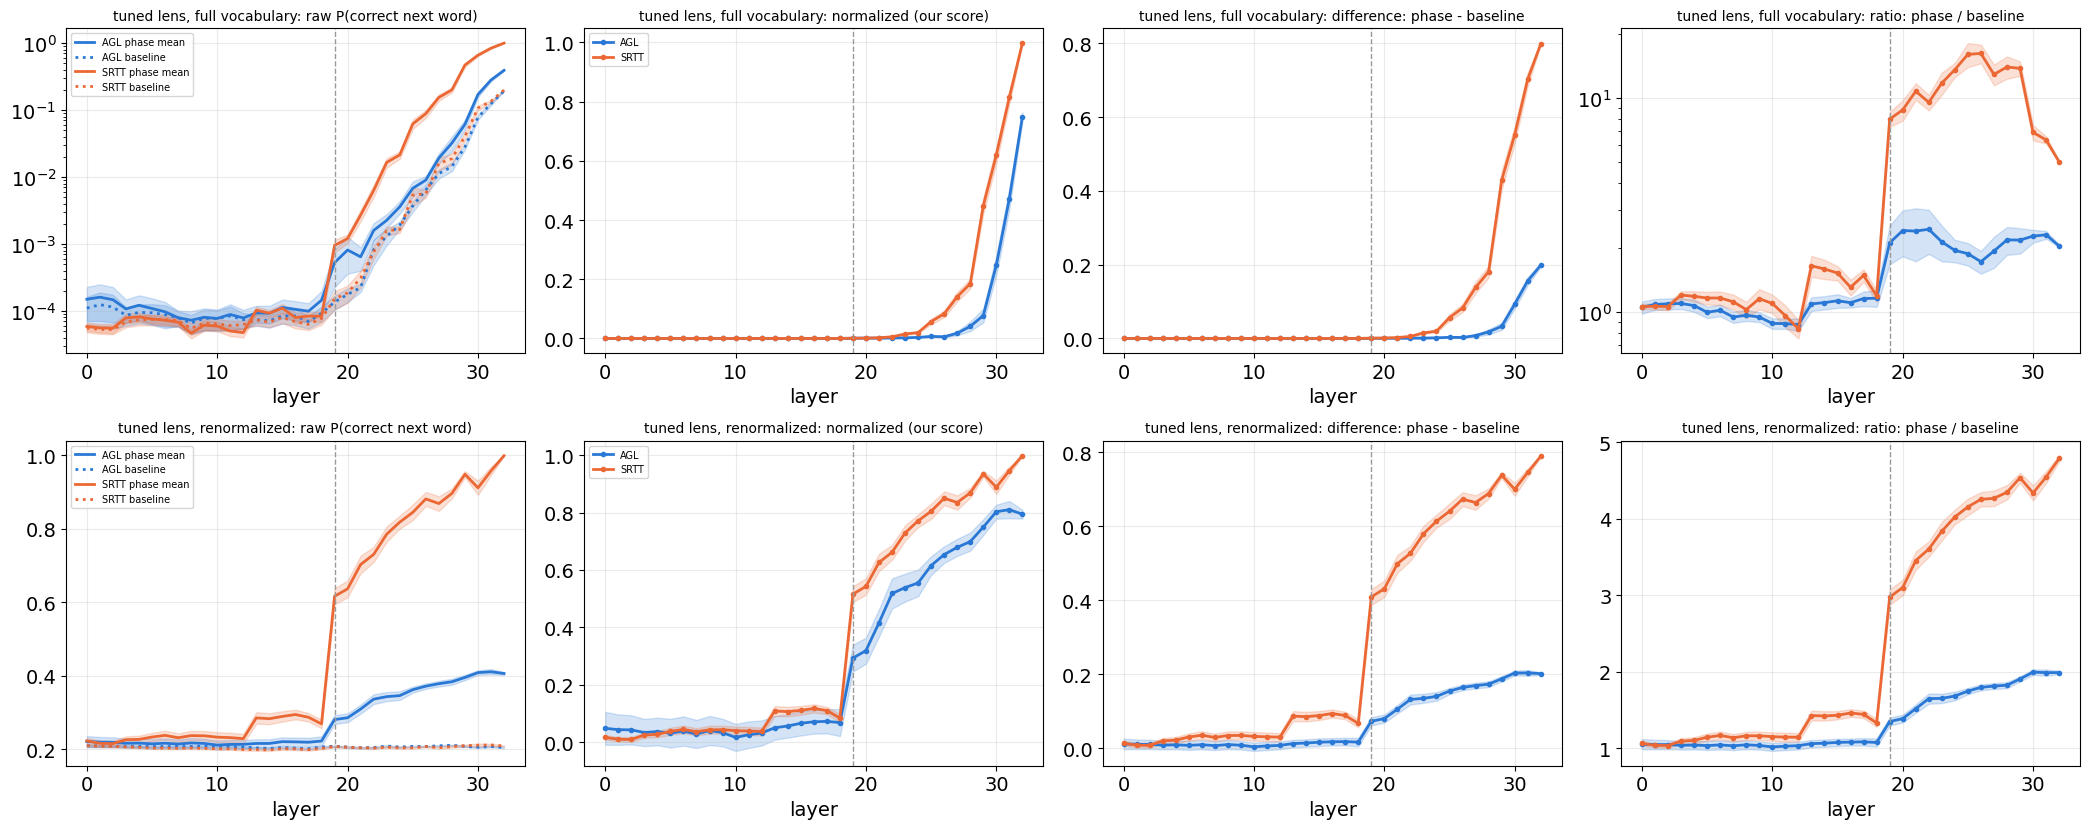

largest one-layer increase at layer  \
lens  metric          grammar version                                           
logit full vocabulary AGL     phase                                        25   
                              normalized                                   30   
                              difference                                   25   
                              ratio                                        19   
                      SRTT    phase                                        25   
                              normalized                                   31   
                              difference                                   31   
                              ratio                                        19   
      renormalized    AGL     phase                                        19   
                              normalized                                   19   
                              difference                                   19   
                              ratio                                        19   
                      SRTT    phase                                        19   
                              normalized                                   19   
                              difference                                   19   
                              ratio                                        19   
tuned full vocabulary AGL     phase                                        32   
                              normalized                                   32   
                              difference                                   31   
                              ratio                                        19   
                      SRTT    phase                                        29   
                              normalized                                   29   
                              difference                                   29   
                              ratio                                        19   
      renormalized    AGL     phase                                        19   
                              normalized                                   19   
                              difference                                   19   
                              ratio                                        19   
                      SRTT    phase                                        19   
                              normalized                                   19   
                              difference                                   19   
                              ratio                                        19   

                                            size  2nd largest at  2nd size  \
lens  metric          grammar version                                        
logit full vocabulary AGL     phase       0.0723              27    0.0457   
                              normalized  0.1132              27    0.1041   
                              difference  0.0326              30    0.0280   
                              ratio       0.4382               6    0.2428   
                      SRTT    phase       0.1713              23    0.1626   
                              normalized  0.1486              25    0.1432   
                              difference  0.1285              23    0.1157   
                              ratio       1.5295              11    0.3755   
      renormalized    AGL     phase       0.1035              21    0.0362   
                              normalized  0.3567              21    0.1397   
                              difference  0.0900              21    0.0360   
                              ratio       0.4390              21    0.1823   
                      SRTT    phase       0.3786              21    0.0808   
                              normalized  0.4608              21    0.0997   
                              differenc

largest one-layer increase at layer 19: 20 of 32 versions (ratio of full-vocabulary probabilities compared on a log scale)


phase mean    ± SE  baseline   ± SE   \
lens  metric          grammar layer                                         
logit full vocabulary AGL     0          0.0001  0.0000    0.0001  0.0000   
                              13         0.0000  0.0000    0.0000  0.0000   
                              18         0.0000  0.0000    0.0001  0.0000   
                              19         0.0002  0.0001    0.0001  0.0000   
                              24         0.0874  0.0159    0.0588  0.0100   
                              32         0.3915  0.0041    0.1926  0.0016   
                      SRTT    0          0.0001  0.0000    0.0001  0.0000   
                              13         0.0001  0.0000    0.0000  0.0000   
                              18         0.0001  0.0000    0.0000  0.0000   
                              19         0.0011  0.0002    0.0001  0.0000   
                              24         0.3016  0.0263    0.0616  0.0077   
                              32         0.9977  0.0003    0.1988  0.0021   
      renormalized    AGL     0          0.1664  0.0062    0.1858  0.0027   
                              13         0.1955  0.0054    0.1883  0.0020   
                              18         0.1946  0.0068    0.1915  0.0023   
                              19         0.2981  0.0091    0.2049  0.0021   
                              24         0.3618  0.0097    0.2038  0.0022   
                              32         0.4059  0.0039    0.2044  0.0015   
                      SRTT    0          0.1474  0.0067    0.1723  0.0023   
                              13         0.2503  0.0075    0.1867  0.0022   
                              18         0.2407  0.0080    0.1922  0.0017   
                              19         0.6193  0.0115    0.2057  0.0021   
                              24         0.7865  0.0234    0.2048  0.0043   
                              32         0.9985  0.0002    0.2087  0.0016   
tuned full vocabulary AGL     0          0.0001  0.0001    0.0001  0.0001   
                              13         0.0001  0.0000    0.0001  0.0000   
                              18         0.0001  0.0001    0.0001  0.0000   
                              19         0.0005  0.0003    0.0001  0.0000   
                              24         0.0036  0.0008    0.0019  0.0003   
                              32         0.3915  0.0041    0.1926  0.0016   
                      SRTT    0          0.0001  0.0000    0.0001  0.0000   
                              13         0.0001  0.0000    0.0001  0.0000   
                              18         0.0001  0.0000    0.0001  0.0000   
                              19         0.0010  0.0002    0.0002  0.0000   
                              24         0.0214  0.0026    0.0016  0.0002   
                              32         0.9977  0.0003    0.1988  0.0021   
      renormalized    AGL     0          0.2206  0.0150    0.2093  0.0026   
                              13         0.2155  0.0112    0.2034  0.0026   
                              18         0.2221  0.0129    0.2060  0.0027   
                              19         0.2805  0.0121    0.2079  0.0022   
                              24         0.3456  0.0118    0.2058  0.0019   
                              32         0.4059  0.0039    0.2044  0.0015   
                      SRTT    0          0.2226  0.0076    0.2095  0.0030   
                              13         0.2850  0.0156    0.1986  0.0030   
                              18         0.2687  0.0119    0.2019  0.0027   
                              19         0.6160  0.0218    0.2071  0.0021   
                              24         0.8176  0.0178    0.2037  0.0027   
                              32         0.9985  0.0002    0.2087  0.0016   

                                      bound  normalized  difference    ratio  
lens  metric          grammar layer                                           
logit full vocabulary AGL   

In [92]:
def se(x):
  return x.std(0, ddof=1) / np.sqrt(len(x))


for lens in LENSES:
  fig, axes = plt.subplots(2, 4, figsize=(21, 8.4))
  for row, metric in zip(axes, METRICS):
    for grammar in ("AGL", "SRTT"):
      s = p1[(lens, metric, grammar)]
      color = SERIES_COLORS[grammar]
      for k, style, label in (("phase", '-', "phase mean"), ("baseline", ':', "baseline")):
        m, e = s[k].mean(0), se(s[k])
        row[0].plot(layer_ids, m, color=color, linestyle=style, linewidth=2, label=f"{grammar} {label}")
        row[0].fill_between(layer_ids, m - e, m + e, color=color, alpha=0.2)
      for ax, k in zip(row[1:], ("normalized", "difference", "ratio")):
        m, e = s[k].mean(0), se(s[k])
        ax.plot(layer_ids, m, color=color, linewidth=2, marker='o', markersize=3, label=grammar)
        ax.fill_between(layer_ids, m - e, m + e, color=color, alpha=0.2)
    if metric == "full vocabulary":
      row[0].set_yscale('log')
      row[3].set_yscale('log')
    for ax, title in zip(row, ("raw P(correct next word)", "normalized (our score)", "difference: phase - baseline",
                               "ratio: phase / baseline")):
      ax.axvline(JUMP_LAYER, color='#9a9a9a', linestyle='--', linewidth=1)
      ax.set_title(f"{lens} lens, {metric}: {title}", fontsize=10)
      ax.set_xlabel("layer")
      ax.grid(alpha=0.25)
    row[0].legend(fontsize=7)
    row[1].legend(fontsize=7)
  fig.tight_layout()
  plt.show()

jump_rows = []
for lens in LENSES:
  for metric in METRICS:
    for grammar in ("AGL", "SRTT"):
      s = p1[(lens, metric, grammar)]
      for version in VERSIONS:
        values = np.log(s[version]) if version == "ratio" and metric == "full vocabulary" else s[version]
        steps = np.diff(values.mean(0))
        order = np.argsort(-steps)
        per_run = np.argmax(np.diff(values, axis=1), axis=1)
        jump_rows.append({"lens": lens, "metric": metric, "grammar": grammar, "version": version,
                          "largest one-layer increase at layer": layer_ids[order[0] + 1],
                          "size": steps[order[0]], "2nd largest at": layer_ids[order[1] + 1], "2nd size": steps[order[1]],
                          f"runs with the largest increase at {JUMP_LAYER}": np.mean([layer_ids[i + 1] == JUMP_LAYER for i in per_run])})
jumps = pd.DataFrame(jump_rows).set_index(["lens", "metric", "grammar", "version"])
display(jumps.round(4))
print(f"largest one-layer increase at layer {JUMP_LAYER}: {(jumps['largest one-layer increase at layer'] == JUMP_LAYER).sum()} "
      f"of {len(jumps)} versions (ratio of full-vocabulary probabilities compared on a log scale)")

raw_rows = []
for lens in LENSES:
  for metric in METRICS:
    for grammar in ("AGL", "SRTT"):
      s = p1[(lens, metric, grammar)]
      for L in RAW_TABLE_LAYERS:
        i = layer_ids.index(L)
        raw_rows.append({"lens": lens, "metric": metric, "grammar": grammar, "layer": L,
                         "phase mean": s["phase"][:, i].mean(), "± SE": se(s["phase"][:, i]),
                         "baseline": s["baseline"][:, i].mean(), "± SE ": se(s["baseline"][:, i]),
                         "bound": s["bound"].mean(), "normalized": s["normalized"][:, i].mean(),
                         "difference": s["difference"][:, i].mean(), "ratio": s["ratio"][:, i].mean()})
display(pd.DataFrame(raw_rows).set_index(["lens", "metric", "grammar", "layer"]).round(4))

## Part 2: our copying score vs. Olsson et al. (2022), and the head selection

### In plain words
**What copying means.** A head *copies* if, when it attends to a token, it raises that same token in the output. Two
ways to measure it:
- **ours (rank-based):** for real positions, where the attended token ranks among all tokens in the head's direct
  contribution to the output, scaled to [−1, 1];
- **Olsson et al.:** from the weights alone. The head's OV circuit maps each input token to output logits:
  W_U · N_final · W_O^h · W_V^h · N_in · W_E, a vocabulary × vocabulary matrix. If its eigenvalues are mostly
  positive, the circuit tends to map a token to itself (copying). Score = sum(eigenvalues) ÷ sum(|eigenvalues|)
  (real parts), in [−1, 1].

**How it is computed without the 32,768 × 32,768 matrix.** Its nonzero eigenvalues equal those of the 128 × 128
matrix (W_V^h · N_in · W_E) · (W_U · N_final · W_O^h) (the same product in the other order).
- W_E · W_U is computed once (4,096 × 4,096).
- The RMSNorm weights (input norm of the layer, final norm) enter as diagonal matrices.
- Mistral shares each value head between 4 query heads (GQA): query head h uses value head h // 4.
- The 8-bit weights are read back as float32 by passing the identity matrix through each layer (one layer at a time).

Sanity checks:
- the read-back weights reproduce each layer's output;
- the trace of the small matrix equals the trace of the full circuit (computed without building it) for a few heads.

**Head selection.** Three sets:
- (a) our top 16 by prefix × copying;
- (b) Olsson-style thresholds: prefix matching ≥ 0.3 and Olsson copying > 0;
- (c) top 16 by prefix matching alone.

If (b) differs from (a) by more than 4 heads, set (b) is switched off on the 20 + 20 streams and compared with (a)
and with 16 random heads.

In [93]:
COMPUTE_DTYPE = model.model.embed_tokens.weight.dtype
DEVICE = model.model.embed_tokens.weight.device


def dense_weight(linear, in_features, chunk=1024):
  """Weight (out, in) as float32, read through the module itself (works for 8-bit, float16 and float32 layers):
  linear(I) = W^T. Done in chunks of the identity to keep memory small."""
  rows = []
  with torch.no_grad():
    for start in range(0, in_features, chunk):
      n = min(chunk, in_features - start)
      eye = torch.zeros(n, in_features, dtype=COMPUTE_DTYPE, device=DEVICE)
      eye[torch.arange(n), start + torch.arange(n)] = 1
      rows.append(linear(eye).float())
  return torch.cat(rows).T.contiguous()


def eigen_copying(matrix):
  lam = torch.linalg.eigvals(matrix.double().cpu())
  return float(lam.sum().real / lam.abs().sum())


assert abs(eigen_copying(torch.eye(8)) - 1) < 1e-9 and abs(eigen_copying(-torch.eye(8)) + 1) < 1e-9

TRACE_CHECK_HEADS = [h for h in [(0, 0), (12, 7), (18, 0), (NUM_LAYERS - 1, NUM_HEADS - 1)] if h[0] < NUM_LAYERS and h[1] < NUM_HEADS]


def olsson_copying_scores():
  path = os.path.join(VAL_DIR, f"olsson_ov_{lens_cache_name('ov')}.npz") if VAL_DIR else None
  if path and os.path.exists(path):
    print(f"loaded OV copying scores from {path}")
    saved = np.load(path)
    return saved["scores"], saved["trace_check"]
  W_E, W_U = model.model.embed_tokens.weight, model.lm_head.weight
  V, d = W_E.shape
  M = torch.zeros(d, d, dtype=torch.float32, device=DEVICE)
  with torch.no_grad():
    for start in range(0, V, 4096):
      M += W_E[start:start + 4096].float().T @ W_U[start:start + 4096].float()  # W_E^T W_U (d x d)
  g_final = model.model.norm.weight.float()
  M_f = M * g_final[None, :]
  n_rep = NUM_HEADS // model.config.num_key_value_heads
  scores = np.zeros((NUM_LAYERS, NUM_HEADS))
  checks = []
  for l in tqdm(range(NUM_LAYERS)):
    attn = model.model.layers[l].self_attn
    W_V = dense_weight(attn.v_proj, d)                      # (kv_heads * head_dim, d)
    W_O = dense_weight(attn.o_proj, NUM_HEADS * HEAD_DIM)   # (d, heads * head_dim)
    if l == 0:  # the read-back weights reproduce the layers
      x = torch.randn(8, d, generator=torch.Generator().manual_seed(0)).to(DEVICE, COMPUTE_DTYPE)
      for name, lin, W, xin in (("v_proj", attn.v_proj, W_V, x), ("o_proj", attn.o_proj, W_O, x[:, :NUM_HEADS * HEAD_DIM])):
        with torch.no_grad():
          real = lin(xin).float()
        rel = ((real - xin.float() @ W.T).norm() / real.norm()).item()
        print(f"[sanity] read-back {name} weight reproduces the layer: relative error {rel:.1e}")
        assert rel < 0.05
    g_in = model.model.layers[l].input_layernorm.weight.float()
    left = (W_V * g_in[None, :]) @ M_f                      # W_V N_in W_E^T W_U N_final  (kv*hd x d)
    for h in range(NUM_HEADS):
      kv = h // n_rep
      small = left[kv * HEAD_DIM:(kv + 1) * HEAD_DIM] @ W_O[:, h * HEAD_DIM:(h + 1) * HEAD_DIM]  # 128 x 128
      scores[l, h] = eigen_copying(small)
      if (l, h) in TRACE_CHECK_HEADS:  # trace of the full V x V circuit, without building it
        full_trace = 0.0
        with torch.no_grad():
          for start in range(0, V, 4096):
            B = (W_U[start:start + 4096].float() * g_final[None, :]) @ W_O[:, h * HEAD_DIM:(h + 1) * HEAD_DIM]   # (chunk, hd)
            A = (W_E[start:start + 4096].float() * g_in[None, :]) @ W_V[kv * HEAD_DIM:(kv + 1) * HEAD_DIM].T  # (chunk, hd)
            full_trace += (B * A).sum().item()
        checks.append((l, h, torch.trace(small).item(), full_trace))
    del W_V, W_O, left
  del M, M_f
  if torch.cuda.is_available():
    torch.cuda.empty_cache()
  checks = np.array(checks)
  if path:
    np.savez(path, scores=scores, trace_check=checks)
  return scores, checks


olsson_scores, trace_check = olsson_copying_scores()
for l, h, small_trace, full_trace in trace_check:
  rel = abs(small_trace - full_trace) / max(abs(full_trace), 1e-12)
  print(f"[sanity] head {int(l)}.{int(h)}: trace of the 128 x 128 matrix {small_trace:.4g} vs. full circuit {full_trace:.4g} "
        f"(relative difference {rel:.1e})")
  assert rel < 1e-2, "the small matrix must have the same trace as the full OV circuit"

loaded OV copying scores from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/olsson_ov_ov_mistral_trained_8bit.npz
[sanity] head 0.0: trace of the 128 x 128 matrix -0.007854 vs. full circuit -0.007854 (relative difference 3.9e-06)
[sanity] head 12.7: trace of the 128 x 128 matrix 0.4775 vs. full circuit 0.4775 (relative difference 1.1e-07)
[sanity] head 18.0: trace of the 128 x 128 matrix 5.386 vs. full circuit 5.386 (relative difference 8.9e-08)
[sanity] head 31.31: trace of the 128 x 128 matrix 9.956 vs. full circuit 9.956 (relative difference 2.4e-08)


,Pearson r,Pearson p,Spearman r,Spearman p
heads,,,,
"all 1,024 heads",0.7596,0.0,0.6671,0.0
top 50 by prefix matching,0.9430,0.0,0.9305,0.0


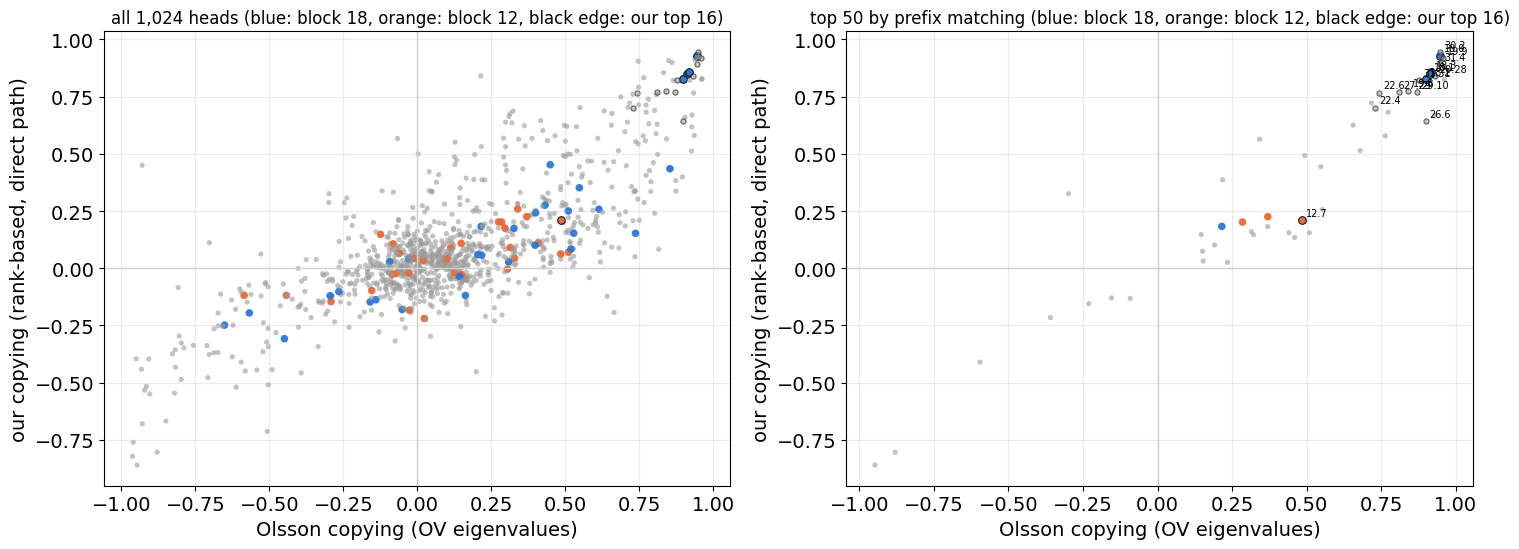

,size,shared with (a),not in (a),(a) heads missing
set,,,,
(a) ours: top 16 by prefix x copying,16,16,-,-
"(b) Olsson thresholds: prefix >= 0.3, OV copying > 0",14,10,"12.6, 2.21, 12.4, 14.18","31.31, 27.29, 22.6, 22.4, 29.10, 18.1"
(c) top 16 by prefix alone,16,8,"28.0, 12.6, 2.21, 12.4, 17.26, 22.29, 14.18, 2...","31.4, 20.28, 31.31, 27.29, 22.6, 22.4, 29.10, ..."
(d) top 16 by prefix x OV copying,16,13,"2.21, 12.6, 24.5","22.6, 22.4, 18.1"


,prefix,our copying,OV copying,in (a),in (b),in (c)
head,,,,,,
18.0,0.932,0.929,0.945,True,True,True
18.2,0.934,0.827,0.900,True,True,True
18.3,0.851,0.858,0.918,True,True,True
19.8,0.522,0.776,0.842,True,True,True
30.2,0.416,0.945,0.949,True,True,True
19.9,0.364,0.917,0.958,True,True,True
26.6,0.452,0.643,0.899,True,True,True
31.4,0.315,0.892,0.946,True,True,False
20.28,0.308,0.838,0.931,True,True,False


(b) differs from (a) by 10 heads (symmetric difference); ablation rerun needed (threshold: more than 4)


In [94]:
from scipy.stats import spearmanr, pearsonr

top50 = np.argsort(-prefix_scores, axis=None)[:50]
corr_rows = []
for label, idx in (("all 1,024 heads", np.arange(prefix_scores.size)), ("top 50 by prefix matching", top50)):
  x, y = copy_scores.ravel()[idx], olsson_scores.ravel()[idx]
  corr_rows.append({"heads": label, "Pearson r": pearsonr(x, y)[0], "Pearson p": pearsonr(x, y)[1],
                    "Spearman r": spearmanr(x, y)[0], "Spearman p": spearmanr(x, y)[1]})
display(pd.DataFrame(corr_rows).set_index("heads").round(4))

top_ref = set(ranked_heads[:K_MAX])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, idx, title in ((axes[0], np.arange(prefix_scores.size), "all 1,024 heads"), (axes[1], top50, "top 50 by prefix matching")):
  for flat in idx:
    l, h = np.unravel_index(flat, prefix_scores.shape)
    color = '#2a78d6' if l == 18 else ('#eb6834' if l == 12 else '#9a9a9a')
    ax.scatter(olsson_scores[l, h], copy_scores[l, h], s=14 if color == '#9a9a9a' else 30, color=color, alpha=0.6 if color == '#9a9a9a' else 0.95,
               edgecolor='#0b0b0b' if (l, h) in top_ref else 'none', linewidth=0.8)
    if (l, h) in top_ref and ax is axes[1]:
      ax.annotate(f"{l}.{h}", (olsson_scores[l, h], copy_scores[l, h]), fontsize=7, xytext=(3, 3), textcoords='offset points')
  ax.axhline(0, color='#d0d0d0', linewidth=1)
  ax.axvline(0, color='#d0d0d0', linewidth=1)
  ax.set_xlabel("Olsson copying (OV eigenvalues)")
  ax.set_ylabel("our copying (rank-based, direct path)")
  ax.set_title(f"{title} (blue: block 18, orange: block 12, black edge: our top 16)")
  ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


def top_k(score_map, k=K_MAX):
  return [tuple(int(v) for v in np.unravel_index(i, score_map.shape)) for i in np.argsort(-score_map, axis=None)[:k]]


set_a = list(ranked_heads[:K_MAX])
set_b = [(int(l), int(h)) for l, h in zip(*np.nonzero((prefix_scores >= PREFIX_THRESHOLD) & (olsson_scores > 0)))]
set_b = sorted(set_b, key=lambda x: -prefix_scores[x])
set_c = top_k(prefix_scores)
set_d = top_k(prefix_scores * np.clip(olsson_scores, 0, None))
sets = {"(a) ours: top 16 by prefix x copying": set_a, f"(b) Olsson thresholds: prefix >= {PREFIX_THRESHOLD}, OV copying > 0": set_b,
        "(c) top 16 by prefix alone": set_c, "(d) top 16 by prefix x OV copying": set_d}
display(pd.DataFrame([{"set": name, "size": len(s), "shared with (a)": len(set(s) & set(set_a)),
                       "not in (a)": ", ".join(f"{l}.{h}" for l, h in s if (l, h) not in set(set_a)) or "-",
                       "(a) heads missing": ", ".join(f"{l}.{h}" for l, h in set_a if (l, h) not in set(s)) or "-"}
                      for name, s in sets.items()]).set_index("set"))
display(pd.DataFrame([{"head": f"{l}.{h}", "prefix": prefix_scores[l, h], "our copying": copy_scores[l, h],
                       "OV copying": olsson_scores[l, h], "in (a)": (l, h) in set(set_a), "in (b)": (l, h) in set(set_b),
                       "in (c)": (l, h) in set(set_c)} for l, h in dict.fromkeys(set_a + set_b + set_c)]).set_index("head").round(3))
sym_diff = len(set(set_a) ^ set(set_b))
print(f"(b) differs from (a) by {sym_diff} heads (symmetric difference); ablation rerun {'needed' if sym_diff > OLSSON_RERUN_MIN_DIFF else 'not needed'} "
      f"(threshold: more than {OLSSON_RERUN_MIN_DIFF})")

### Switching off the threshold set (only if it differs from our top 16 by more than 4 heads)
Learning score at the model's output (full vocabulary), per run, on the 20 + 20 streams of `05`. Compared, run by run,
with no switch-off, our top 16 (a) and 16 random heads, as mean ± 95% bootstrap interval.

In [95]:
ablation_rows = []
if sym_diff > OLSSON_RERUN_MIN_DIFF:
  for grammar in ("AGL", "SRTT"):
    scores = {name: final_learning(run05(name, heads, grammar), val_prompts[grammar])
              for name, heads in (("baseline", []), (f"all{K_MAX}", set_a), ("olsson_set", set_b),
                                  (f"random{K_MAX}_draw0", conditions[f"random{K_MAX}_draw0"]["heads"]))}
    for name, values in scores.items():
      m, lo, hi = mean_ci(values)
      row = {"grammar": grammar, "heads switched off": name, "n heads": {"baseline": 0, "olsson_set": len(set_b)}.get(name, K_MAX),
             "learning": m, "95% CI": f"[{lo:.3f}, {hi:.3f}]"}
      if name != "baseline":
        dm, dlo, dhi = mean_ci(values - scores["baseline"])
        row["change vs. none"], row["change 95% CI"] = dm, f"[{dlo:.3f}, {dhi:.3f}]"
      ablation_rows.append(row)
    dm, dlo, dhi = mean_ci(scores["olsson_set"] - scores[f"all{K_MAX}"])
    print(f"{grammar}: threshold set (b) minus top 16 (a): {dm:+.3f} [{dlo:+.3f}, {dhi:+.3f}], sign-flip p = {sign_flip_p(scores['olsson_set'] - scores[f'all{K_MAX}']):.4f}")
  display(pd.DataFrame(ablation_rows).set_index(["grammar", "heads switched off"]).round(3))
else:
  print("the threshold set is close to our top 16: no extra ablation needed")

loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_baseline_b6639803_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_all16_5204773d_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_olsson_set_77135022_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_random16_draw0_4209ec37_n20.pkl
AGL: threshold set (b) minus top 16 (a): -0.075 [-0.099, -0.051], sign-flip p = 0.0001
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/srtt_mistral_trained_8bit_baseline_b6639803_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/srtt_mistral_trained_8bit_all16_5204773d_n20.pkl
loaded 20 runs 

n heads  learning          95% CI  \
grammar heads switched off                                      
AGL     baseline                  0     0.749  [0.718, 0.776]   
        all16                    16     0.393  [0.341, 0.445]   
        olsson_set               14     0.318  [0.276, 0.360]   
        random16_draw0           16     0.751  [0.719, 0.777]   
SRTT    baseline                  0     0.997  [0.996, 0.998]   
        all16                    16     0.730  [0.691, 0.768]   
        olsson_set               14     0.910  [0.889, 0.930]   
        random16_draw0           16     0.997  [0.996, 0.998]   

                            change vs. none     change 95% CI  
grammar heads switched off                                     
AGL     baseline                        NaN               NaN  
        all16                        -0.356  [-0.396, -0.316]  
        olsson_set                   -0.431  [-0.466, -0.395]  
        random16_draw0                0.002   [-0.002, 0.005]  
SRTT    baseline                        NaN               NaN  
        all16                        -0.267  [-0.306, -0.229]  
        olsson_set                   -0.087  [-0.108, -0.068]  
        random16_draw0               -0.000   [-0.000, 0.000]

## Part 3a: reading map controls

### In plain words
In `06` the reading map showed each induction head putting its attention on the earlier words of the transition being
predicted (a dark diagonal). Two controls:
- **Random heads:** the same map for 4 random non-induction heads from blocks 18–19. Expected: no diagonal.
- **Permutation baseline:** within each run, the transition labels of the earlier grammar words are shuffled 100 times
  (attention untouched). For each head, the **diagonal share** (attention on the predicted transition's own earlier
  words ÷ attention on all earlier grammar words) with the real labels is compared with the 100 shuffled values:
  p = (1 + number of shuffles ≥ real) ÷ 101.

A shuffle keeps how many words each transition has, so the shuffled share is the share that word frequency alone would
give.

random non-induction control heads: [(18, 22), (18, 10), (19, 11), (19, 6)]
loaded AGL reading map + permutations from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/readingperm_agl_mistral_trained_8bit_5_400_100_d8e87fac.pkl
loaded SRTT reading map + permutations from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/readingperm_srtt_mistral_trained_8bit_5_400_100_d8e87fac.pkl


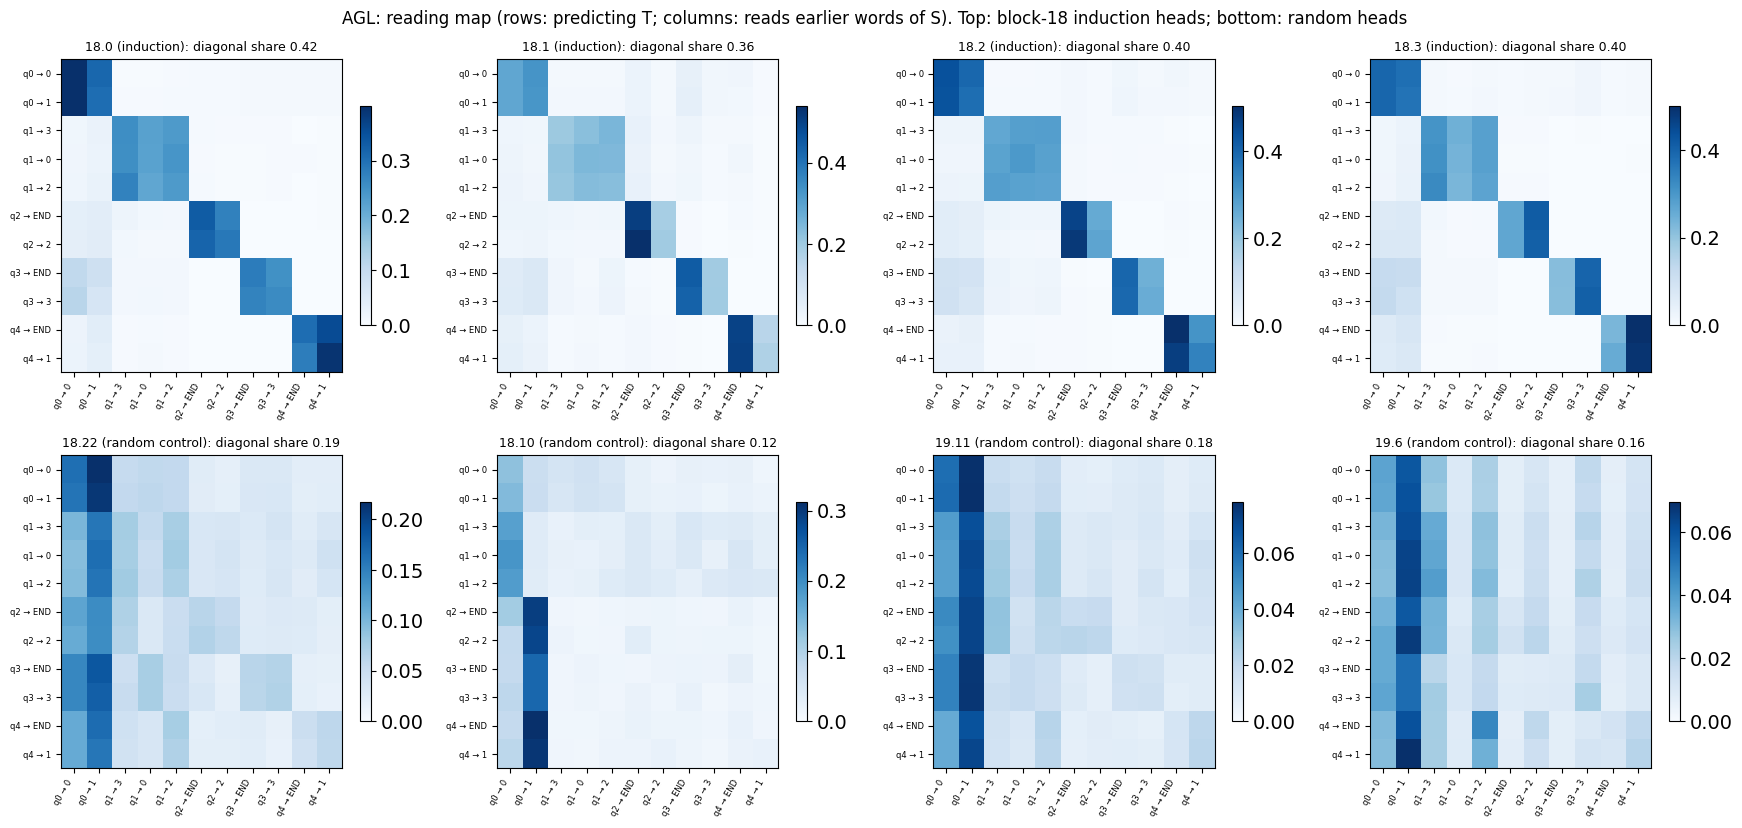

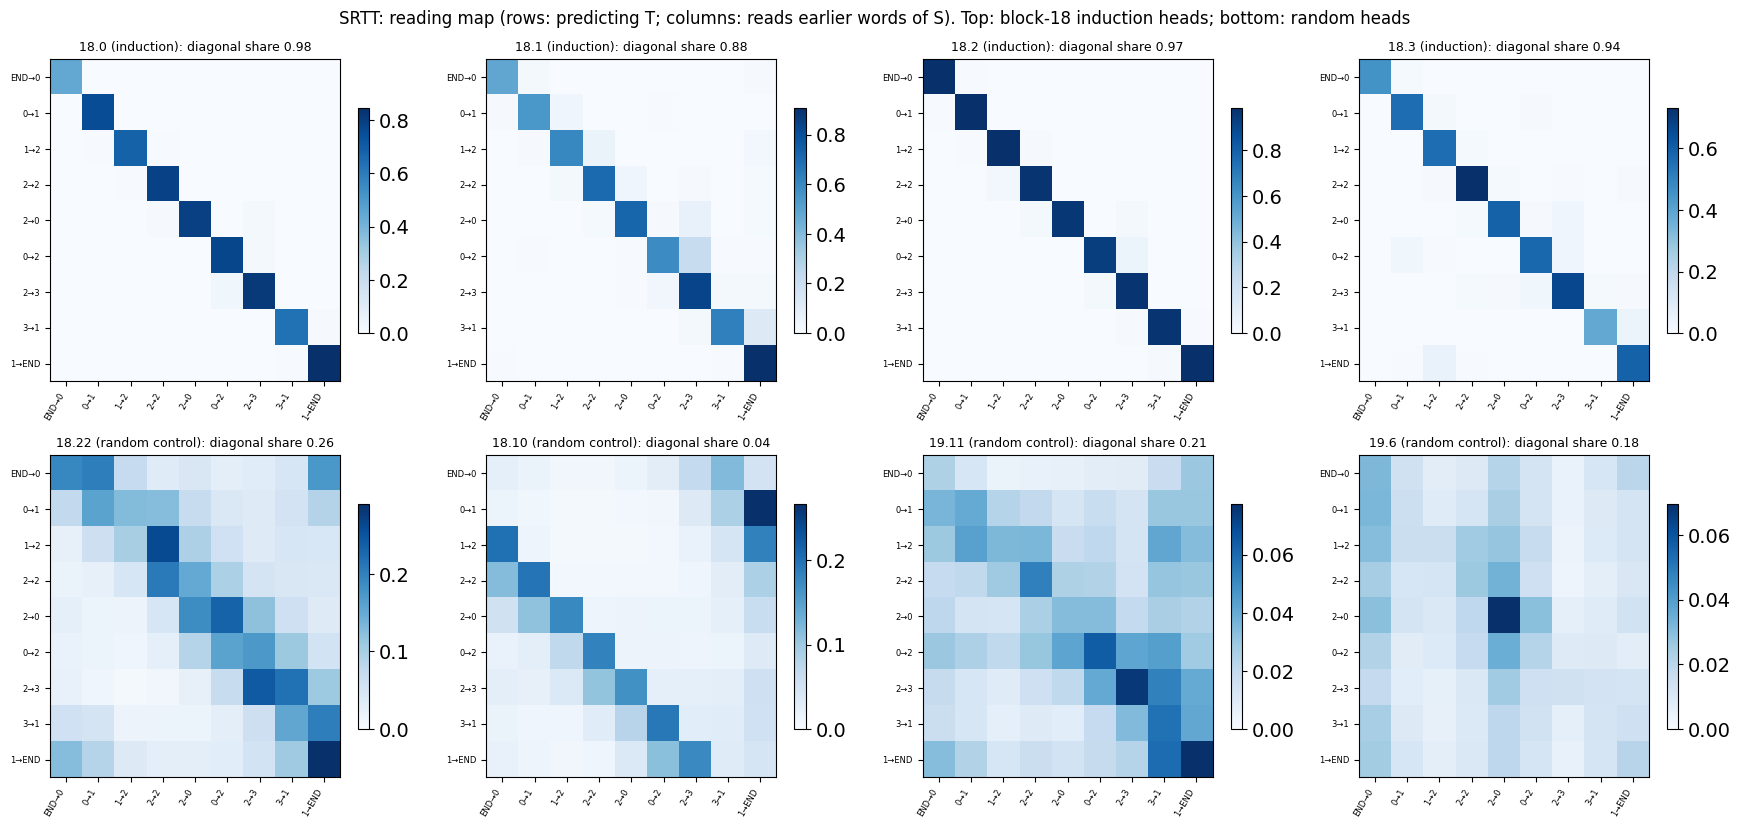

diagonal share (real)  shuffled: mean  \
grammar kind               head                                           
AGL     induction (top 16) 12.7                  0.4410          0.1581   
                           18.0                  0.4162          0.1594   
                           18.1                  0.3642          0.1561   
                           18.2                  0.4017          0.1590   
                           18.3                  0.3974          0.1577   
                           19.8                  0.2963          0.1565   
                           19.9                  0.2777          0.1573   
                           20.28                 0.2849          0.1575   
                           22.4                  0.2485          0.1540   
                           22.6                  0.2940          0.1555   
                           26.6                  0.3304          0.1533   
                           27.29                 0.2566          0.1509   
                           29.10                 0.3102          0.1595   
                           30.2                  0.2554          0.1460   
                           31.31                 0.2697          0.1567   
                           31.4                  0.2959          0.1606   
        random control     18.10                 0.1222          0.1569   
                           18.22                 0.1875          0.1620   
                           19.11                 0.1822          0.1576   
                           19.6                  0.1565          0.1563   
SRTT    induction (top 16) 12.7                  0.9967          0.1116   
                           18.0                  0.9829          0.1115   
                           18.1                  0.8752          0.1112   
                           18.2                  0.9743          0.1117   
                           18.3                  0.9355          0.1113   
                           19.8                  0.6860          0.1114   
                           19.9                  0.5331          0.1112   
                           20.28                 0.5447          0.1112   
                           22.4                  0.5569          0.1115   
                           22.6                  0.5739          0.1115   
                           26.6                  0.6945          0.1109   
                           27.29                 0.4300          0.1112   
                           29.10                 0.5820          0.1115   
                           30.2                  0.6414          0.1115   
                           31.31                 0.6102          0.1115   
                           31.4                  0.5182          0.1111   
        random control     18.10                 0.0437          0.1114   
                           18.22                 0.2566          0.1110   
                           19.11                 0.2106          0.1111   
                           19.6                  0.1828          0.1112   

                                  shuffled: 95th pct  p (permutation)  
grammar kind               head                                        
AGL     induction (top 16) 12.7               0.1627           0.0099  
                           18.0               0.1646           0.0099  
                           18.1               0.1600           0.0099  
                           18.2               0.1631           0.0099  
                           18.3               0.1614           0.0099  
                           19.8               0.1590           0.0099  
                           19.9               0.1591           0.0099  
                           20.28              0.1595           0.0099  
                           22.4               0.1576           0.0099  
                           22.6               0.1595           0.0099  
                   

                            heads  p < 0.05  mean share real  \
grammar kind                                                   
AGL     induction (top 16)   16.0      16.0            0.321   
        random control        4.0       2.0            0.162   
SRTT    induction (top 16)   16.0      16.0            0.696   
        random control        4.0       3.0            0.173   

                            mean share shuffled  
grammar kind                                     
AGL     induction (top 16)                0.156  
        random control                    0.158  
SRTT    induction (top 16)                0.111  
        random control                    0.111  


In [96]:
rng_control = np.random.default_rng(2024)
RANDOM_CONTROL_HEADS = []
for i, block in enumerate(CONTROL_BLOCKS):
  pool = [(block, h) for h in range(NUM_HEADS) if (block, h) not in excluded]
  n = N_CONTROL_HEADS // len(CONTROL_BLOCKS) + (1 if i < N_CONTROL_HEADS % len(CONTROL_BLOCKS) else 0)
  RANDOM_CONTROL_HEADS += [pool[j] for j in rng_control.choice(len(pool), size=n, replace=False)]
print("random non-induction control heads:", RANDOM_CONTROL_HEADS)
assert not set(RANDOM_CONTROL_HEADS) & excluded


def reading_map_perm(grammar, heads, n_runs=READING_RUNS):
  """The 06 reading map plus, per head, the diagonal share with the real labels and with N_PERMUTATIONS_MAP
  within-run shuffles of the earlier words' transition labels."""
  path = os.path.join(VAL_DIR, f"readingperm_{lens_cache_name(grammar.lower())}_{n_runs}_{READING_QUERIES}_{N_PERMUTATIONS_MAP}_"
                               f"{hashlib.md5(repr(heads).encode()).hexdigest()[:8]}.pkl") if VAL_DIR else None
  if path and os.path.exists(path):
    with open(path, 'rb') as f:
      print(f"loaded {grammar} reading map + permutations from {path}")
      return pickle.load(f)
  device = get_device()
  order = TRANSITION_ORDER[grammar]
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  sums = {head: np.zeros((len(order), len(order))) for head in heads}
  counts = np.zeros(len(order))
  own, total = defaultdict(float), defaultdict(float)
  own_perm = {head: np.zeros(N_PERMUTATIONS_MAP) for head in heads}
  rng = np.random.default_rng(0)
  for p in tm_prompts[grammar][:n_runs]:
    info = stream_info(p, grammar)
    ids = prepare_lens_inputs(tokenizer, p)["input_ids"]
    window = np.sort(rng.choice(np.arange(info["le"] - LAST_N_STRUCTURED, info["le"]), size=min(READING_QUERIES, LAST_N_STRUCTURED), replace=False))
    rows = torch.as_tensor(window, device=device)
    targets = torch.as_tensor([order.index(info["labels"][t]) for t in window], device=device)
    src = np.concatenate([info["positions"][S] for S in order])
    src_label = np.concatenate([np.full(len(info["positions"][S]), k) for k, S in enumerate(order)])
    src_t = torch.as_tensor(src, dtype=torch.long, device=device)
    onehot = torch.nn.functional.one_hot(torch.as_tensor(src_label, device=device), len(order)).float()          # (n_src, n_S)
    perms = np.stack([rng.permutation(src_label) for _ in range(N_PERMUTATIONS_MAP)])
    onehot_perm = torch.nn.functional.one_hot(torch.as_tensor(perms, device=device), len(order)).float()          # (n_perm, n_src, n_S)

    def callback(layer, h, probs):
      rows_probs = probs[rows].float()
      rows_probs[torch.arange(len(rows), device=device), rows] = 0   # the query's own word is not an earlier occurrence
      A = rows_probs[:, src_t]                                         # (n_q, n_src): attention on earlier grammar words
      by_source = A @ onehot                                           # (n_q, n_S)
      np.add.at(sums[(layer, h)], targets.cpu().numpy(), by_source.cpu().numpy())
      own[(layer, h)] += by_source.gather(1, targets[:, None]).sum().item()
      total[(layer, h)] += A.sum().item()
      shuffled = torch.einsum('qs,psk->pqk', A, onehot_perm)           # (n_perm, n_q, n_S)
      own_perm[(layer, h)] += shuffled.gather(2, targets[None, :, None].expand(len(perms), -1, 1)).sum((1, 2)).cpu().numpy()

    _ko.update(callback=callback, callback_heads=dict(by_layer))
    try:
      with torch.no_grad(), knockout([], lambda key: None):
        model(input_ids=ids.to(device), use_cache=False)
    finally:
      _ko.update(callback=None, callback_heads={})
    for t in targets.cpu().numpy():
      counts[t] += 1
  result = {"maps": {f"{l}.{h}": pd.DataFrame(sums[(l, h)] / np.maximum(counts, 1)[:, None], index=order, columns=order) for l, h in heads},
            "share": {f"{l}.{h}": own[(l, h)] / max(total[(l, h)], 1e-12) for l, h in heads},
            "null": {f"{l}.{h}": own_perm[(l, h)] / max(total[(l, h)], 1e-12) for l, h in heads}}
  if path:
    with open(path, 'wb') as f:
      pickle.dump(result, f)
  return result


map_heads = list(dict.fromkeys(GROUP_HEADS + SINGLE_HEADS + RANDOM_CONTROL_HEADS))
reading_perm = {g: reading_map_perm(g, map_heads) for g in ("AGL", "SRTT")}

show_heads = [f"{l}.{h}" for l, h in SINGLE_HEADS][:4] + [f"{l}.{h}" for l, h in RANDOM_CONTROL_HEADS]
for grammar in ("AGL", "SRTT"):
  fig, axes = plt.subplots(2, max(4, len(show_heads) - 4), figsize=(4.4 * max(4, len(show_heads) - 4), 8.4), squeeze=False)
  for ax, name in zip(axes.ravel(), show_heads):
    frame = reading_perm[grammar]["maps"][name]
    im = ax.imshow(frame.values, cmap='Blues', vmin=0, aspect='auto')
    ax.set_xticks(range(len(frame.columns)))
    ax.set_xticklabels(frame.columns, rotation=60, ha='right', fontsize=6)
    ax.set_yticks(range(len(frame.index)))
    ax.set_yticklabels(frame.index, fontsize=6)
    kind = "random control" if name in [f"{l}.{h}" for l, h in RANDOM_CONTROL_HEADS] else "induction"
    ax.set_title(f"{name} ({kind}): diagonal share {reading_perm[grammar]['share'][name]:.2f}", fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.7)
  fig.suptitle(f"{grammar}: reading map (rows: predicting T; columns: reads earlier words of S). Top: block-18 induction heads; bottom: random heads")
  fig.tight_layout()
  plt.show()

perm_rows = []
for grammar in ("AGL", "SRTT"):
  for name in reading_perm[grammar]["share"]:
    real, null = reading_perm[grammar]["share"][name], reading_perm[grammar]["null"][name]
    perm_rows.append({"grammar": grammar, "head": name,
                      "kind": "random control" if name in [f"{l}.{h}" for l, h in RANDOM_CONTROL_HEADS] else "induction (top 16)",
                      "diagonal share (real)": real, "shuffled: mean": null.mean(), "shuffled: 95th pct": np.percentile(null, 95),
                      "p (permutation)": (1 + np.sum(null >= real)) / (1 + len(null))})
perm_table = pd.DataFrame(perm_rows).set_index(["grammar", "kind", "head"]).sort_index()
display(perm_table.round(4))
print(perm_table.groupby(level=["grammar", "kind"]).apply(
  lambda d: pd.Series({"heads": len(d), "p < 0.05": int((d["p (permutation)"] < 0.05).sum()),
                       "mean share real": d["diagonal share (real)"].mean(), "mean share shuffled": d["shuffled: mean"].mean()})).round(3))

## Part 3b: leave-one-in controls

### In plain words
In `05` (Step C), all top-16 induction heads were switched off and one was given back; what it restored measured that
head's own contribution. The control asks how much **any** head restores in the same situation.

A random non-induction head is normally on, so "giving it back" only means something if it was off: the control
condition switches off the 16 induction heads **plus** the random head, and its restoration is the difference between
having that head on and off, with the 16 induction heads off in both. This is exactly how the induction heads were
measured. Expected: about 0.

Four random non-induction heads from blocks 18–19 (the same as in Part 3a), on the same 20 + 20 streams, paired. Two
measures, next to the 16 induction heads of `05`:
- restored learning score at the output, as a share of the loss from switching off all 16 (± 95% CI);
- restored P(correct next word), mean over transitions.

loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_baseline_b6639803_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_all16_5204773d_n20.pkl
[AGL] 05 Step C for 18.0: not found: head_specialization/agl_mistral_trained_8bit_allbut_18_0_d5f91385_n20
[AGL] 05 Step C for 18.2: not found: head_specialization/agl_mistral_trained_8bit_allbut_18_2_b62189fe_n20
[AGL] 05 Step C for 18.3: not found: head_specialization/agl_mistral_trained_8bit_allbut_18_3_e0023282_n20
[AGL] 05 Step C for 19.8: not found: head_specialization/agl_mistral_trained_8bit_allbut_19_8_8c66e35a_n20
[AGL] 05 Step C for 30.2: not found: head_specialization/agl_mistral_trained_8bit_allbut_30_2_a7e193f2_n20
[AGL] 05 Step C for 19.9: not found: head_specialization/agl_mistral_trained_8bit_allbut_19_9_be99c33e_n20
[AGL] 05 Step C for 26.6: not found: head_specialization/agl_mi

restored learning            95% CI  \
grammar kind           head                                         
AGL     random control 18.22             0.0032    [0.001, 0.005]   
                       18.10             0.0052    [0.003, 0.007]   
                       19.11             0.0006   [-0.000, 0.001]   
                       19.6             -0.0001   [-0.001, 0.001]   
SRTT    random control 18.22            -0.0153  [-0.021, -0.010]   
                       18.10             0.0047    [0.002, 0.008]   
                       19.11            -0.0006   [-0.001, 0.000]   
                       19.6              0.0006   [-0.000, 0.002]   

                              share of the loss  \
grammar kind           head                       
AGL     random control 18.22             0.0091   
                       18.10             0.0146   
                       19.11             0.0016   
                       19.6             -0.0004   
SRTT    random control 18.22            -0.0572   
                       18.10             0.0177   
                       19.11            -0.0022   
                       19.6              0.0023   

                              restored P(correct), mean over transitions  \
grammar kind           head                                                
AGL     random control 18.22                                      0.0002   
                       18.10                                      0.0009   
                       19.11                                      0.0003   
                       19.6                                      -0.0000   
SRTT    random control 18.22                                     -0.0124   
                       18.10                                      0.0040   
                       19.11                                     -0.0005   
                       19.6                                       0.0005   

                              sign-flip p  
grammar kind           head                
AGL     random control 18.22       0.0099  
                       18.10       0.0001  
                       19.11       0.1797  
                       19.6        0.7737  
SRTT    random control 18.22       0.0001  
                       18.10       0.0125  
                       19.11       0.1392  
                       19.6        0.2160

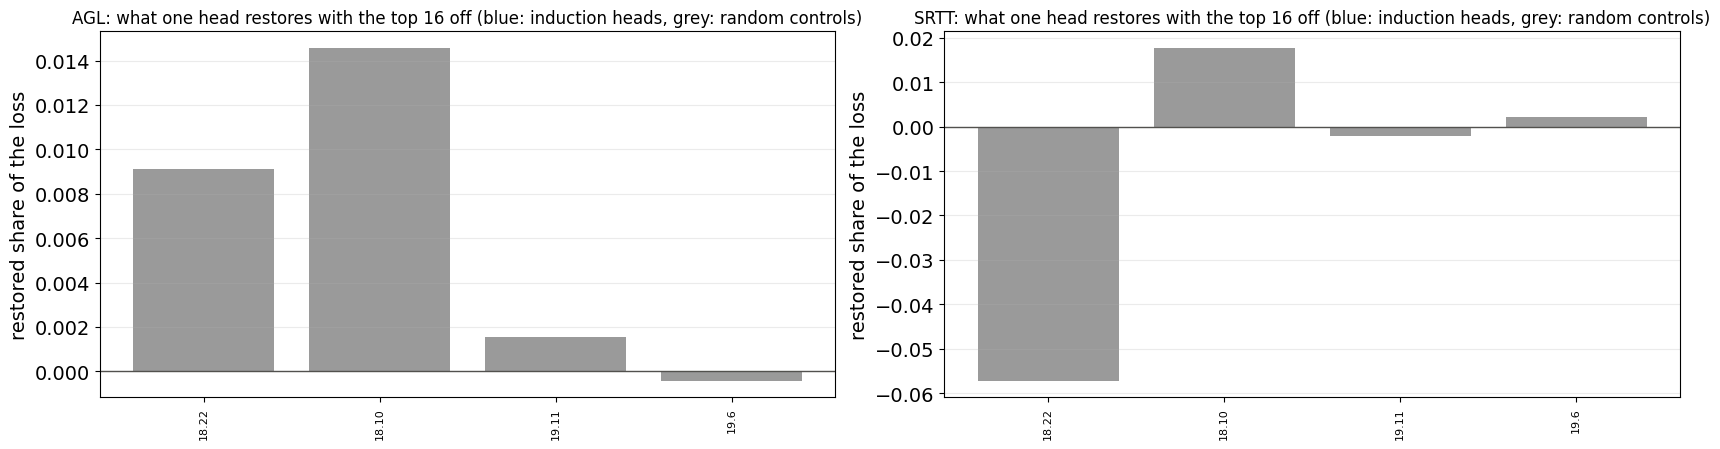

In [97]:
loi = {}  # (grammar, head name, kind) -> {"learning": per-run restored, "transition": per-run per-transition restored}
loi_rows = []
for grammar in ("AGL", "SRTT"):
  base_res = run05("baseline", [], grammar)
  all_res = run05(f"all{K_MAX}", induction_sets[K_MAX], grammar)
  base_l, all_l = final_learning(base_res, val_prompts[grammar]), final_learning(all_res, val_prompts[grammar])
  all_t = per_transition_probs(all_res, val_prompts[grammar], grammar)
  loss = (base_l - all_l).mean()
  entries = []
  for l, h in induction_sets[K_MAX]:  # 05 Step C: all 16 off except (l, h) -- loaded only
    saved, message = load_only(cond05_cache_name(f"allbut_{l}_{h}", [x for x in induction_sets[K_MAX] if x != (l, h)], grammar), val_prompts[grammar])
    if saved is None:
      print(f"[{grammar}] 05 Step C for {l}.{h}: {message}")
      continue
    entries.append((f"{l}.{h}", "induction head kept (05)", saved["logit"], all_res))  # on = kept, off = all 16 off
  for l, h in RANDOM_CONTROL_HEADS:
    off_res = run05(f"all{K_MAX}_plus_{l}_{h}", induction_sets[K_MAX] + [(l, h)], grammar)
    entries.append((f"{l}.{h}", "random control", all_res, off_res))  # on = all 16 off, off = all 16 + this head off
  for name, kind, on_res, off_res in entries:
    restored_l = final_learning(on_res, val_prompts[grammar]) - final_learning(off_res, val_prompts[grammar])
    restored_t = (per_transition_probs(on_res, val_prompts[grammar], grammar).values
                  - per_transition_probs(off_res, val_prompts[grammar], grammar).values)
    loi[(grammar, name, kind)] = {"learning": restored_l, "transition": restored_t}
    m, lo, hi = mean_ci(restored_l)
    loi_rows.append({"grammar": grammar, "kind": kind, "head": name, "restored learning": m, "95% CI": f"[{lo:.3f}, {hi:.3f}]",
                     "share of the loss": m / loss, "restored P(correct), mean over transitions": restored_t.mean(),
                     "sign-flip p": sign_flip_p(restored_l)})
loi_table = pd.DataFrame(loi_rows).set_index(["grammar", "kind", "head"])
display(loi_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6))
for ax, grammar in zip(axes, ("AGL", "SRTT")):
  sub = loi_table.loc[grammar].reset_index()
  colors = ['#2a78d6' if k.startswith("induction") else '#9a9a9a' for k in sub["kind"]]
  ax.bar(range(len(sub)), sub["share of the loss"], color=colors)
  ax.set_xticks(range(len(sub)))
  ax.set_xticklabels(sub["head"], rotation=90, fontsize=8)
  ax.axhline(0, color='#52514e', linewidth=1)
  ax.set_ylabel("restored share of the loss")
  ax.set_title(f"{grammar}: what one head restores with the top 16 off (blue: induction heads, grey: random controls)")
  ax.grid(alpha=0.25, axis='y')
fig.tight_layout()
plt.show()

## Part 3c: FDR correction for every heatmap with significance stars

### In plain words
Our heatmaps star a cell when its change exceeds 3 standard errors. With ~100 cells per map, some stars can appear by
chance. Here every cell gets a p-value (paired t-test over runs), and the Benjamini–Hochberg procedure keeps the
expected share of false stars at 5% within each map.

Maps, all loaded from Drive (nothing is recomputed; a map whose results are missing is skipped):
- `06` attention knockout: top 16, its two controls, and the four block-18 heads, for both grammars;
- `05` Step C (what one head restores, per transition);
- the random-head controls of Part 3b.

The table gives, per map: cells starred by the 3-SE rule, cells surviving FDR, and how many diagonal cells survive.
Random-control maps should have (almost) none.

[06 head18.1, SRTT] skipped: a blocked condition is missing
[06 head18.2, AGL] skipped: not found: transition_memory/agl_mistral_trained_8bit_head18.2_noblock_n10
[06 head18.2, SRTT] skipped: not found: transition_memory/srtt_mistral_trained_8bit_head18.2_noblock_n10
[06 head18.3, AGL] skipped: not found: transition_memory/agl_mistral_trained_8bit_head18.3_noblock_n10
[06 head18.3, SRTT] skipped: not found: transition_memory/srtt_mistral_trained_8bit_head18.3_noblock_n10


random control  runs  cells  \
source      map                      grammar                                
06 knockout group16                  AGL               False    10    121   
                                     SRTT              False    10     81   
            group16_randompos        AGL                True    10    121   
                                     SRTT               True    10     81   
            random16                 AGL                True    10    121   
                                     SRTT               True    10     81   
            head18.0                 AGL               False    10    121   
                                     SRTT              False    10     81   
            head18.1                 AGL               False    10    121   
3b          3b: random head restored AGL                True    20     44   
                                     SRTT               True    20     36   

                                              stars (> 3 SE)  FDR q < 0.05  \
source      map                      grammar                                 
06 knockout group16                  AGL                  65            71   
                                     SRTT                 19            10   
            group16_randompos        AGL                  51            54   
                                     SRTT                 13             0   
            random16                 AGL                  12             1   
                                     SRTT                  2             0   
            head18.0                 AGL                  65            70   
                                     SRTT                  2             0   
            head18.1                 AGL                  47            51   
3b          3b: random head restored AGL                   4             3   
                                     SRTT                  5             4   

                                             diagonal: FDR / cells  \
source      map                      grammar                         
06 knockout group16                  AGL                   11 / 11   
                                     SRTT                    6 / 9   
            group16_randompos        AGL                   11 / 11   
                                     SRTT                    0 / 9   
            random16                 AGL                    1 / 11   
                                     SRTT                    0 / 9   
            head18.0                 AGL                   11 / 11   
                                     SRTT                    0 / 9   
            head18.1                 AGL                   11 / 11   
3b          3b: random head restored AGL                       NaN   
                                     SRTT                      NaN   

                                              off-diagonal FDR  
source      map                      grammar                    
06 knockout group16                  AGL                  60.0  
                                     SRTT                  4.0  
            group16_randompos        AGL                  43.0  
                                     SRTT                  0.0  
            random16                 AGL                   0.0  
                                     SRTT                  0.0  
            head18.0                 AGL                  59.0  
                                     SRTT                  0.0  
            head18.1                 AGL                  40.0  
3b          3b: random head restored AGL                   NaN  
                                     SRTT                  NaN

random-control maps: 87 cells starred by the 3-SE rule, 62 surviving FDR (of 484 cells)


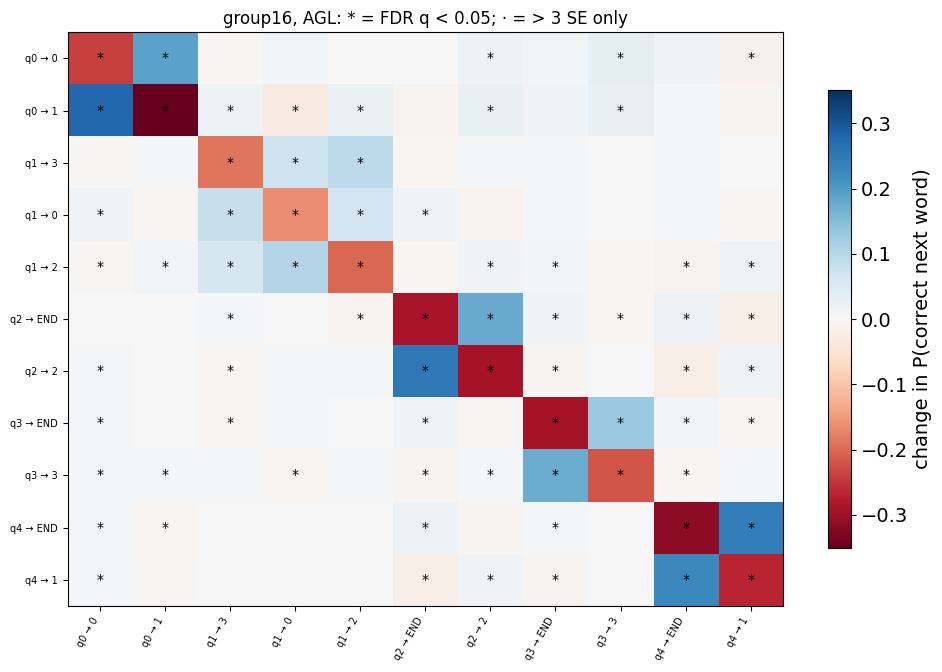

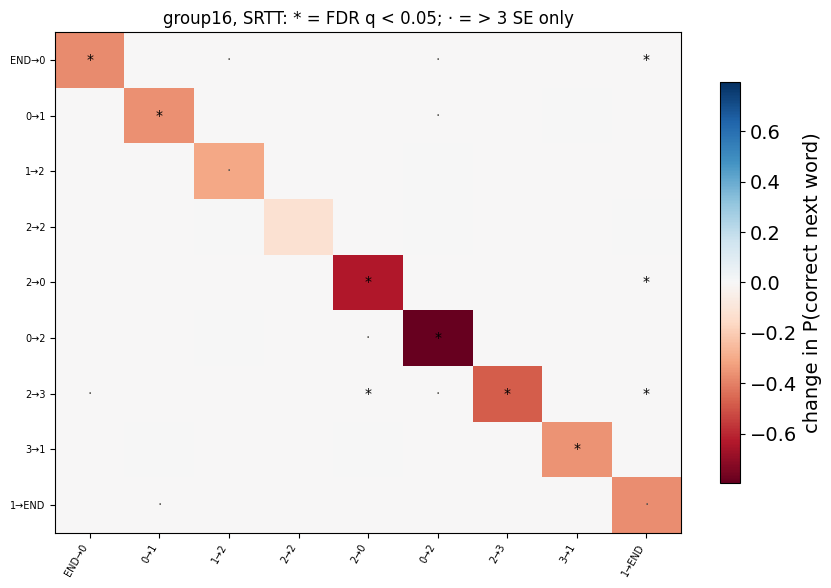

In [98]:
def load_tm(name, grammar):
  saved, message = load_only(tm_cache_name(name, grammar), tm_prompts[grammar])
  return (None, message) if saved is None else (per_transition_probs(saved["logit"], tm_prompts[grammar], grammar), "ok")


def tm_cache_name(name, grammar):
  return f"transition_memory/{lens_cache_name(grammar.lower())}_{name}_n{N_RUNS_TM}"


fdr_maps = {}  # (source, map, grammar) -> (diff (runs, rows, cols), row labels, col labels, is_control, has_diagonal)
tm_sets = [("group16", "group16", False), ("group16_randompos", "group16", True), ("random16", "random16", True)] + \
          [(f"head{l}.{h}", f"head{l}.{h}", False) for l, h in SINGLE_HEADS]
for label, base, is_control in tm_sets:
  for grammar in ("AGL", "SRTT"):
    order = TRANSITION_ORDER[grammar]
    base_df, message = load_tm(f"{base}_noblock", grammar)
    rows_ = [load_tm(f"{label}_S{i}", grammar)[0] for i in range(len(order))]
    if base_df is None or any(r is None for r in rows_):
      print(f"[06 {label}, {grammar}] skipped: {message if base_df is None else 'a blocked condition is missing'}")
      continue
    diff = np.stack([r.values - base_df.values for r in rows_], axis=1)  # (runs, S, T)
    fdr_maps[("06 knockout", label, grammar)] = (diff, order, order, is_control, True)
for grammar in ("AGL", "SRTT"):
  for kind, title, control in (("induction head kept (05)", "05 Step C: one head restored", False), ("random control", "3b: random head restored", True)):
    names = [name for (g, name, k) in loi if g == grammar and k == kind]
    if names:
      diff = np.stack([loi[(grammar, n, kind)]["transition"] for n in names], axis=1)  # (runs, heads, T)
      fdr_maps[(title.split(":")[0], title, grammar)] = (diff, names, TRANSITION_ORDER[grammar], control, False)

fdr_rows, fdr_marks = [], {}
for key, (diff, rows_, cols, is_control, diagonal) in fdr_maps.items():
  mean = diff.mean(0)
  se_ = diff.std(0, ddof=1) / np.sqrt(diff.shape[0])
  p = cell_pvalues(diff)
  q = bh_qvalues(p)
  three_se = np.abs(mean) > SIGNIFICANT_SE * se_
  fdr = q < FDR_Q
  fdr_marks[key] = (mean, three_se, fdr)
  row = {"source": key[0], "map": key[1], "grammar": key[2], "random control": is_control, "runs": diff.shape[0],
         "cells": mean.size, "stars (> 3 SE)": int(three_se.sum()), f"FDR q < {FDR_Q}": int(fdr.sum())}
  if diagonal:
    eye = np.eye(len(rows_), dtype=bool)
    row["diagonal: FDR / cells"] = f"{int(fdr[eye].sum())} / {len(rows_)}"
    row["off-diagonal FDR"] = int(fdr[~eye].sum())
  fdr_rows.append(row)
fdr_table = pd.DataFrame(fdr_rows).set_index(["source", "map", "grammar"])
display(fdr_table)
controls = fdr_table[fdr_table["random control"]]
print(f"random-control maps: {int(controls['stars (> 3 SE)'].sum())} cells starred by the 3-SE rule, "
      f"{int(controls[f'FDR q < {FDR_Q}'].sum())} surviving FDR (of {int(controls['cells'].sum())} cells)")

plot_keys = [k for k in fdr_maps if k[1] in ("group16", "05 Step C: one head restored")]
for key in plot_keys:
  mean, three_se, fdr = fdr_marks[key]
  _, rows_, cols, _, _ = fdr_maps[key]
  fig, ax = plt.subplots(figsize=(0.62 * len(cols) + 3, 0.42 * len(rows_) + 2.2))
  limit = max(np.abs(mean).max(), 1e-6)
  im = ax.imshow(mean, cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
  for i, j in zip(*np.nonzero(fdr)):
    ax.text(j, i, "*", ha='center', va='center', fontsize=10)
  for i, j in zip(*np.nonzero(three_se & ~fdr)):
    ax.text(j, i, "·", ha='center', va='center', fontsize=10, color='#52514e')
  ax.set_xticks(range(len(cols)))
  ax.set_xticklabels(cols, rotation=60, ha='right', fontsize=7)
  ax.set_yticks(range(len(rows_)))
  ax.set_yticklabels(rows_, fontsize=7)
  ax.set_title(f"{key[1]}, {key[2]}: * = FDR q < {FDR_Q}; · = > 3 SE only")
  fig.colorbar(im, ax=ax, shrink=0.8, label="change in P(correct next word)")
  fig.tight_layout()
  plt.show()

## Part 3d: noise, as paired differences

### In plain words
`04` compared layers at the same general damage (0.05 nats of extra Wikipedia loss), but its error bars were for the
learning *level* in each condition, not for the *difference* from no noise on the same stream.

Here, for every lens layer from 15 to 22:
1. The noise size giving 0.05 nats of damage is read from `04`'s saved Wikipedia losses (interpolated on a log scale
   between the noise sizes tested there; layers 16 and 21 were not in `04` and get their damage curve computed).
2. The real damage at that size is measured.
3. The 20 + 20 streams run with that noise. Per stream: learning with noise minus learning without (the saved `05`
   baseline).

We report:
- the mean difference with a 95% bootstrap interval, per layer;
- a **paired test of layers 15–18 vs. 19–22:** per stream, the mean change over 15–18 minus the mean change over
  19–22 (bootstrap interval, sign-flip p, t-test p).

(The `04` stream results were computed before the stream fix, so they are rerun; the noise for a stream depends only
on its tokens and the layer, as in `04`. The suggested random-direction control in the subspace orthogonal to the top
principal components is not included; the paired test is the requested alternative.)

loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_baseline_b6639803_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_noise_L15_a0.6206_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_noise_L16_a0.6168_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_noise_L17_a0.5366_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_noise_L18_a0.4948_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_8bit_noise_L19_a0.4671_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/metric_validation/agl_mistral_trained_

matched alpha  damage at alpha (nats)  learning without noise  \
grammar layer                                                                  
AGL     15            0.6206                  0.0372                  0.7491   
        16            0.6168                  0.0387                  0.7491   
        17            0.5366                  0.0367                  0.7491   
        18            0.4948                  0.0348                  0.7491   
        19            0.4671                  0.0368                  0.7491   
        20            0.4322                  0.0395                  0.7491   
        21            0.4112                  0.0455                  0.7491   
        22            0.4053                  0.0479                  0.7491   
SRTT    15            0.6206                  0.0372                  0.9971   
        16            0.6168                  0.0387                  0.9971   
        17            0.5366                  0.0367                  0.9971   
        18            0.4948                  0.0348                  0.9971   
        19            0.4671                  0.0368                  0.9971   
        20            0.4322                  0.0395                  0.9971   
        21            0.4112                  0.0455                  0.9971   
        22            0.4053                  0.0479                  0.9971   

               change            95% CI  sign-flip p  
grammar layer                                         
AGL     15    -0.0543  [-0.062, -0.046]       0.0001  
        16    -0.0492  [-0.056, -0.043]       0.0001  
        17    -0.0522  [-0.057, -0.047]       0.0001  
        18    -0.0526  [-0.058, -0.047]       0.0001  
        19    -0.0141  [-0.017, -0.011]       0.0001  
        20    -0.0064  [-0.010, -0.003]       0.0021  
        21    -0.0098  [-0.013, -0.007]       0.0001  
        22    -0.0023   [-0.005, 0.001]       0.1411  
SRTT    15    -0.0008  [-0.001, -0.001]       0.0001  
        16    -0.0021  [-0.003, -0.002]       0.0001  
        17    -0.0024  [-0.003, -0.002]       0.0001  
        18    -0.0011  [-0.001, -0.001]       0.0001  
        19    -0.0007  [-0.001, -0.001]       0.0001  
        20    -0.0001   [-0.000, 0.000]       0.4079  
        21    -0.0001  [-0.000, -0.000]       0.0605  
        22    -0.0001   [-0.000, 0.000]       0.2308

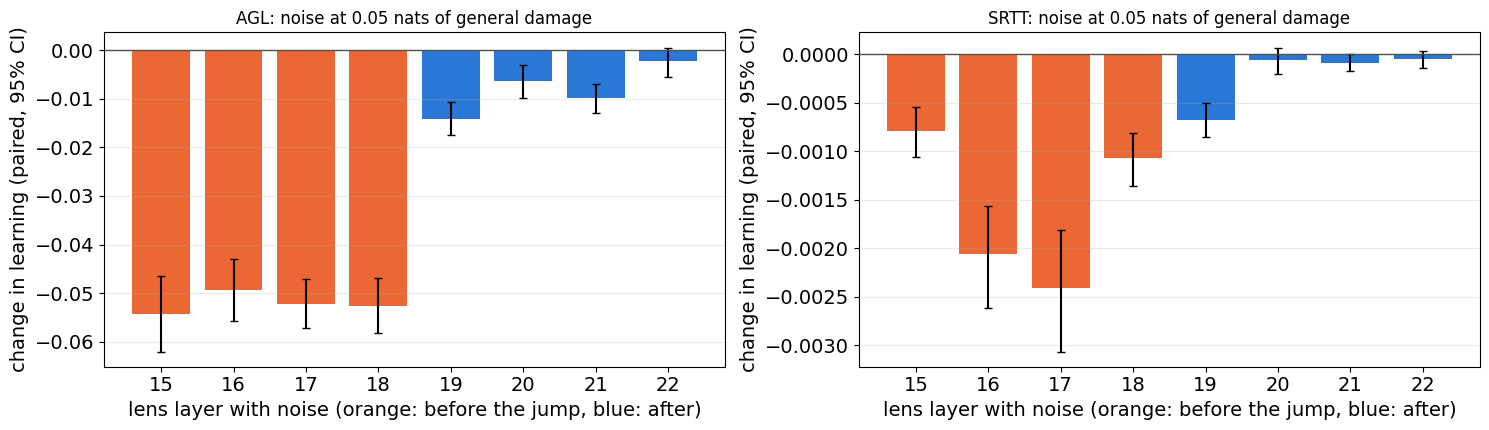

AGL: change before the jump minus after, per stream: -0.0439 [-0.0482, -0.0397] (95% CI); sign-flip p = 0.0001; t-test p = 0.0000; streams where before < after: 20 of 20
SRTT: change before the jump minus after, per stream: -0.0014 [-0.0017, -0.0010] (95% CI); sign-flip p = 0.0001; t-test p = 0.0000; streams where before < after: 20 of 20


In [99]:
_noise_seed = {"value": 0}


def _seed_from_input(module, args, kwargs):
  """Derives the noise seed from the input tokens, so a run gets the same noise whenever it is recomputed."""
  ids = kwargs.get("input_ids", args[0] if args else None)
  _noise_seed["value"] = int(ids.long().sum().item() * 7919 + ids.shape[-1]) % (2 ** 31)


@contextmanager
def add_noise(model, layer, alpha, salt=0):
  """Adds random noise of relative size alpha to every token's state (except BOS) at lens layer `layer`,
  i.e. on the output of block layer-1. alpha = 0 or layer = None: no noise. (Identical to 04.)"""
  if not alpha or layer is None:
    yield
    return

  def hook(module, args, out):
    h = out[0] if isinstance(out, tuple) else out
    generator = torch.Generator(device=h.device).manual_seed(_noise_seed["value"] + 1000003 * layer + salt)
    noise = torch.randn(h.shape, generator=generator, device=h.device, dtype=torch.float32)
    h32 = h.float()
    noise = noise / noise.norm(dim=-1, keepdim=True) * alpha * h32.norm(dim=-1, keepdim=True)
    noise[:, 0] = 0  # leave BOS alone
    noisy = (h32 + noise).to(h.dtype)
    return (noisy,) + tuple(out[1:]) if isinstance(out, tuple) else noisy

  handles = [model.register_forward_pre_hook(_seed_from_input, with_kwargs=True),
             model.model.layers[layer - 1].register_forward_hook(hook)]
  try:
    yield
  finally:
    for handle in handles:
      handle.remove()


_wiki = {}


def noise_wiki_losses(name, layer, alpha):
  """Per-sequence mean next-token loss on held-out Wikipedia with the noise on (same files as 04)."""
  path = os.path.join(NOISE_DIR, f"wiki_{lens_cache_name('wiki')}_{name}_{NOISE_WIKI_SEQS}.npy") if NOISE_DIR else None
  if path and os.path.exists(path):
    return np.load(path)
  if "tokens" not in _wiki:
    _wiki["tokens"] = load_lens_training_tokens(tokenizer, NOISE_WIKI_SEQS, 512, "test")
  device = get_device()
  losses = []
  with torch.no_grad(), add_noise(model, layer, alpha, salt=1):
    for start in range(0, len(_wiki["tokens"]), NOISE_WIKI_BATCH):
      batch = _wiki["tokens"][start:start + NOISE_WIKI_BATCH].to(device)
      logprobs = torch.log_softmax(model(input_ids=batch, use_cache=False).logits.float(), dim=-1)
      losses.append((-logprobs[:, :-1].gather(-1, batch[:, 1:, None]).squeeze(-1)).mean(-1).cpu())
  losses = torch.cat(losses).numpy()
  if path:
    np.save(path, losses)
  return losses


clean_wiki = noise_wiki_losses("baseline", None, 0.0)


def matched_alpha(L):
  """Noise size giving DAMAGE_LEVEL nats of extra Wikipedia loss at lens layer L (log-scale interpolation)."""
  damage = np.maximum.accumulate([(noise_wiki_losses(f"L{L}_a{a:g}", L, a) - clean_wiki).mean() for a in NOISE_ALPHAS])
  if damage[-1] < DAMAGE_LEVEL:
    return np.nan, damage
  i = int(np.argmax(damage >= DAMAGE_LEVEL))
  if i == 0:
    return NOISE_ALPHAS[0] * DAMAGE_LEVEL / max(damage[0], 1e-12), damage
  x0, x1, y0, y1 = np.log(NOISE_ALPHAS[i - 1]), np.log(NOISE_ALPHAS[i]), damage[i - 1], damage[i]
  return float(np.exp(x0 + (DAMAGE_LEVEL - y0) / max(y1 - y0, 1e-12) * (x1 - x0))), damage


noise_rows, noise_diff = [], {}
for grammar in NOISE_GRAMMARS:
  clean = final_learning(run05("baseline", [], grammar), val_prompts[grammar])
  for L in NOISE_BEFORE + NOISE_AFTER:
    alpha, damage = matched_alpha(L)
    if not np.isfinite(alpha):
      print(f"layer {L}: the largest noise size gives only {damage[-1]:.3f} nats; skipped")
      continue
    real_damage = (noise_wiki_losses(f"L{L}_a{alpha:.4f}", L, alpha) - clean_wiki).mean()
    with add_noise(model, L, alpha):
      noisy_res = run_lens_extraction(model, tokenizer, val_prompts[grammar], [NUM_LAYERS],
                                      cache_name=f"metric_validation/{lens_cache_name(grammar.lower())}_noise_L{L}_a{alpha:.4f}_n{VAL_RUNS}")["logit"]
    noise_diff[(grammar, L)] = final_learning(noisy_res, val_prompts[grammar]) - clean
    m, lo, hi = mean_ci(noise_diff[(grammar, L)])
    noise_rows.append({"grammar": grammar, "layer": L, "matched alpha": alpha, "damage at alpha (nats)": real_damage,
                       "learning without noise": clean.mean(), "change": m, "95% CI": f"[{lo:.3f}, {hi:.3f}]", "_lo": lo, "_hi": hi,
                       "sign-flip p": sign_flip_p(noise_diff[(grammar, L)])})
if not noise_rows:
  print("no layer reached the damage level: nothing to compare")
noise_table = pd.DataFrame(noise_rows, columns=["grammar", "layer", "matched alpha", "damage at alpha (nats)", "learning without noise",
                                                "change", "95% CI", "_lo", "_hi", "sign-flip p"]).set_index(["grammar", "layer"])
display(noise_table.drop(columns=["_lo", "_hi"]).round(4))

fig, axes = plt.subplots(1, len(NOISE_GRAMMARS), figsize=(7.5 * len(NOISE_GRAMMARS), 4.4), squeeze=False)
for ax, grammar in zip(axes[0], NOISE_GRAMMARS):
  if grammar not in noise_table.index.get_level_values(0):
    continue
  sub = noise_table.loc[grammar]
  colors = ['#eb6834' if L in NOISE_BEFORE else '#2a78d6' for L in sub.index]
  ax.bar(range(len(sub)), sub["change"], color=colors,
         yerr=[sub["change"] - sub["_lo"], sub["_hi"] - sub["change"]], capsize=3)
  ax.set_xticks(range(len(sub)))
  ax.set_xticklabels(sub.index)
  ax.axhline(0, color='#52514e', linewidth=1)
  ax.set_xlabel("lens layer with noise (orange: before the jump, blue: after)")
  ax.set_ylabel("change in learning (paired, 95% CI)")
  ax.set_title(f"{grammar}: noise at {DAMAGE_LEVEL:g} nats of general damage")
  ax.grid(alpha=0.25, axis='y')
fig.tight_layout()
plt.show()

for grammar in NOISE_GRAMMARS:
  before = [noise_diff[(grammar, L)] for L in NOISE_BEFORE if (grammar, L) in noise_diff]
  after = [noise_diff[(grammar, L)] for L in NOISE_AFTER if (grammar, L) in noise_diff]
  if before and after:
    contrast = np.mean(before, axis=0) - np.mean(after, axis=0)   # per stream: (mean change 15-18) - (mean change 19-22)
    m, lo, hi = mean_ci(contrast)
    print(f"{grammar}: change before the jump minus after, per stream: {m:+.4f} [{lo:+.4f}, {hi:+.4f}] (95% CI); "
          f"sign-flip p = {sign_flip_p(contrast):.4f}; t-test p = {stats.ttest_1samp(contrast, 0).pvalue:.4f}; "
          f"streams where before < after: {int((contrast < 0).sum())} of {len(contrast)}")

## Summary of the checks

The cell below collects the main numbers in one table: the criterion, the value, and whether it passes.

In [100]:
verdicts = []
n_jump = (jumps["largest one-layer increase at layer"] == JUMP_LAYER)
main_versions = jumps.xs("renormalized", level="metric")
verdicts.append({"part": "1", "check": f"largest one-layer increase at layer {JUMP_LAYER} (renormalized, every lens/grammar/version)",
                 "value": f"{int((main_versions['largest one-layer increase at layer'] == JUMP_LAYER).sum())} of {len(main_versions)}",
                 "pass": bool((main_versions['largest one-layer increase at layer'] == JUMP_LAYER).all())})
verdicts.append({"part": "1", "check": f"... including full vocabulary", "value": f"{int(n_jump.sum())} of {len(jumps)}", "pass": bool(n_jump.all())})
r_all = corr_rows[0]
verdicts.append({"part": "2", "check": "our copying vs. Olsson copying, Spearman over 1,024 heads", "value": f"{r_all['Spearman r']:.2f}",
                 "pass": bool(r_all["Spearman r"] > 0.5)})
verdicts.append({"part": "2", "check": "threshold set (b) vs. our top 16 (a): heads in the symmetric difference", "value": str(sym_diff),
                 "pass": bool(sym_diff <= OLSSON_RERUN_MIN_DIFF) or None})
ctrl = perm_table.xs("random control", level="kind")
ind = perm_table.xs("induction (top 16)", level="kind")
verdicts.append({"part": "3a", "check": "induction heads: diagonal share above shuffled (p < 0.05)",
                 "value": f"{int((ind['p (permutation)'] < 0.05).sum())} of {len(ind)}", "pass": None})
verdicts.append({"part": "3a", "check": "random heads: diagonal share above shuffled (p < 0.05)",
                 "value": f"{int((ctrl['p (permutation)'] < 0.05).sum())} of {len(ctrl)}", "pass": bool((ctrl['p (permutation)'] >= 0.05).all())})
ctrl_loi = loi_table.xs("random control", level="kind")
verdicts.append({"part": "3b", "check": "random head restored (share of the loss), largest |value|",
                 "value": f"{ctrl_loi['share of the loss'].abs().max():.3f}", "pass": bool(ctrl_loi['share of the loss'].abs().max() < 0.05)})
verdicts.append({"part": "3c", "check": "random-control heatmap cells surviving FDR",
                 "value": f"{int(controls[f'FDR q < {FDR_Q}'].sum())} of {int(controls['cells'].sum())}",
                 "pass": bool(controls[f'FDR q < {FDR_Q}'].sum() <= 0.05 * controls['cells'].sum())})
main = fdr_table.loc[[k for k in fdr_table.index if k[1] == "group16"]] if len(fdr_table) else fdr_table
if len(main):
  verdicts.append({"part": "3c", "check": "06 top-16 knockout: diagonal cells surviving FDR",
                   "value": "; ".join(f"{g}: {v}" for (_, _, g), v in main["diagonal: FDR / cells"].items()), "pass": None})
display(pd.DataFrame(verdicts).set_index(["part", "check"]))

value  \
part check                                                                           
1    largest one-layer increase at layer 19 (renorma...                   16 of 16   
     ... including full vocabulary                                        20 of 32   
2    our copying vs. Olsson copying, Spearman over 1...                       0.67   
     threshold set (b) vs. our top 16 (a): heads in ...                         10   
3a   induction heads: diagonal share above shuffled ...                   32 of 32   
     random heads: diagonal share above shuffled (p ...                     5 of 8   
3b   random head restored (share of the loss), large...                      0.057   
3c   random-control heatmap cells surviving FDR                          62 of 484   
     06 top-16 knockout: diagonal cells surviving FDR    AGL: 11 / 11; SRTT: 6 / 9   

                                                          pass  
part check                                                      
1    largest one-layer increase at layer 19 (renorma...   True  
     ... including full vocabulary                       False  
2    our copying vs. Olsson copying, Spearman over 1...   True  
     threshold set (b) vs. our top 16 (a): heads in ...   None  
3a   induction heads: diagonal share above shuffled ...   None  
     random heads: diagonal share above shuffled (p ...  False  
3b   random head restored (share of the loss), large...  False  
3c   random-control heatmap cells surviving FDR          False  
     06 top-16 knockout: diagonal cells surviving FDR     None

## How to interpret the results

**Part 1 passes** if the largest one-layer increase is at layer 19 in the raw phase mean, under every normalization
and with both lenses. Then the jump is a property of the model, not of our score.
- The baseline should be flat across 18 → 19, so the jump comes from the phase mean.
- If the full-vocabulary ratio peaks elsewhere, check the raw table: at early layers both numbers are tiny, and a ratio
  of two tiny numbers is unstable. That is a weakness of the ratio, not of the finding.
- The share of single runs with the largest increase at 19 tells whether the jump holds per stream or only on average.

**Part 2 passes** if our copying correlates strongly with Olsson's, and the threshold set matches our top 16 or, when
it does not, gives the same ablation effect.
- Spearman over all heads is the main number: most heads are near 0 in both scores, so a high Pearson value is easy.
- The block-18 and block-12 heads should be on the same side in both scores. Block 12 looked but barely copied in our
  score; if Olsson's score agrees, the "block 12 matches but does not copy" reading is confirmed.

**Part 3 passes** if every control is near zero and the main effects survive FDR.
- **3a:** induction heads with a diagonal share well above the shuffled values (small p), random heads not.
- **3b:** random heads restore about 0, far below the induction heads.
- **3c:** the diagonal of the `06` top-16 knockout survives FDR; random-control maps keep at most a few cells (about 5%
  of cells may pass by chance at q = 0.05).
- **3d:** a negative before-minus-after contrast whose interval excludes 0 confirms that noise just before block 18
  costs more learning than noise after it, at equal general damage. An interval including 0 means the `04` difference
  is not established with 20 streams.